# Realtime vs offline decoding — when do they disagree?

This notebook compares, bin by bin, what the **realtime decoder** (causal, with a random-walk prior)
decoded against the **offline decoder** (`decode_hex_any`) for the same recording, and asks:

1. **When are they more likely to disagree?** Speed, spike supply, location, ripples, confidence, time in session.
2. **When they disagree, how many of those bins had no — or very few — spikes** for the realtime decoder?
3. **How much of the disagreement is fixable?** Softer scoring, confidence gating and thresholds, and a slower prior.

**Run:** Toby · 2025-03-16 · session 07 · `r4_merged_random_no_preload`.

**Agreement rule.** The realtime decode *agrees* with offline when it is **within `AGREE_TOL` = 1 hex step** of the
offline decode on the maze graph (so the same hex or a neighbour). Exact-hex numbers are shown alongside where useful.

**Error bars.** Shaded bands and whiskers are **95% confidence intervals from a block bootstrap**: the epoch is cut
into 30 s blocks and whole blocks are resampled (500×). Neighbouring 6 ms bins are far from independent, so the
usual binomial error bars would be much too narrow.

**Three things to keep in mind**

- **The offline decode is acausal** (a smoother — it uses future bins too); the realtime decoder only ever sees the past.
  Some disagreement is therefore expected by design, especially at moments where the future changes the answer.
- **The realtime prior is a random walk with variance 1 hop² per 6 ms bin.** This was verified directly: re-running the
  update from the logged likelihoods with that matrix reproduces the logged posterior to 2e-16 (§14). The realtime file
  is named `..._uniform_transmat.pkl`, but that name is stale — it is *not* the uniform prior.
- **A zero-spike bin is not "prior only".** The realtime likelihood always includes a no-spike term
  (`decoder_process.py:308-316`) that favours hexes where cells rarely fire, so a zero-spike bin = prior × that bias.

**Colours.** When decoders are compared: <span style="color:#2b5c9e">**blue = realtime**</span>,
<span style="color:#d0663a">**orange = offline**</span>, <span style="color:#3c9a7b">**green = rat's true hex**</span>.
When behavioural state is compared: <span style="color:#9a8fcc">**light violet = still**</span>,
<span style="color:#5a4a9c">**dark violet = running**</span>. Grey = reference / baseline. Heatmaps use seaborn's
*mako* scale (light = low, dark = high). All of these pass the colour-blind-safety checks (OKLab ΔE under simulated
protan/deutan vision).

---
## Summary

1. **They disagree on 57% of bins** under the 1-hex rule (80% by exact hex). In those bins, offline is almost
   always the one near the rat (81% vs 7%), so a disagreement mostly means the realtime decode is off. (§3)
2. **Speed is the strongest outside factor.** Disagreement is 64–70% below 20 cm/s and 37–38% above 50 cm/s. With
   speed held fixed, spikes only help while running fast; at rest, more spikes mean *more* disagreement. (§4, §5)
3. **A lack of spikes is not the explanation.** 16.7% of disagreeing bins had zero spikes, against 14.6% of
   agreeing bins. Only 0.7% had no spikes in the last 30 ms. (§6)
4. **Rest is where it breaks.** Disagreement episodes longer than a second are mostly at the corners (84%), and at rest
   corners 1 and 3 are at 80–93%. High-spike rest bins are partly replay-like (ripples, non-local offline content),
   and realtime matches offline on that content only 22% of the time. (§7–§9, A6)
5. **The realtime decode jumps hex 89 times per second**, 10× offline and 50× the rat, because its prior spreads
   belief about 150 hex steps per second. (§8, §14)
6. **Much of it is fixable.** Replaying the filter with a slower prior (`movement_var` ≈ 0.1–0.2 instead of 1)
   raises agreement from 43% to 54–58% and cuts jumping to 13–33 switches/s, while keeping agreement on non-local
   content at 21–25%. Stickier priors look better overall but erase the non-local content. (§14)
7. **Confidence ranks bins well but overstates itself.** Thresholding the posterior peak at 0.4–0.5 raises agreement
   to 67–70% while still leaving 30–46 usable bins per second. But when the decoder says it is 45% sure of a hex, it is
   right 29% of the time. (§11, §12)
8. **Thresholding keeps little non-local content, and most of realtime's non-local decodes are errors.** Realtime
   calls 57% of bins non-local (offline: 13%), and at ≥ 0.5 only 13% of its surviving non-local bins agree with
   offline. Where offline is non-local, a high threshold does help: at ≥ 0.9, realtime agrees with offline's far
   (5+ hex) content 57% of the time, but few such bins survive. Counted as events, 71% of offline's non-local events
   still have a passing bin at ≥ 0.5. (§12b–12f)
9. **Barrier shifts barely move the disagreement; behaviour and the empty encoder do.** Realtime decodes a
   closed hex in 6.8% of bins, but telling it where the barriers are raises agreement only from 43% to 45.5%, and
   the shifts cause no consistent jump. The worst stretches are a ~3-minute pause after the first shift (the rat
   standing mid-maze next to the newly opened hex) and the first minutes of this no-preload run. (§13)


## 0 · Setup

Set `FIG_DIR` to a folder to also save every figure as a PDF (text stays editable) and a 300-dpi PNG.

In [1]:
import collections, glob, os, sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.patches import RegularPolygon
from scipy.stats import rankdata

REPO = '/home/andy-quach/realtime_decoder'
sys.path.insert(0, REPO)
from realtime_decoder import transitions

# fixed colour roles (see the intro); validated as a colour-blind-safe set
RT, OF, TRUE = '#2b5c9e', '#d0663a', '#3c9a7b'           # realtime / offline / rat's true hex
STILL_C, RUN_C = '#b3a9d9', '#5a4a9c'                    # behavioural state: light = still, dark = running
INK, INK2, MUTED, SHADE = '#222222', '#555555', '#8c8c8c', '#eeeeee'
# sequential: seaborn "mako", light -> dark, stopped short of its near-black end
CM_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    'mako_soft', sns.color_palette('mako_r', as_cmap=True)(np.linspace(0, 0.78, 256)))

def text_on(rgba):
    # white text on dark cells, dark text on light ones (by the cell colour's luminance)
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    return 'white' if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.25 else INK

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Liberation Sans', 'Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9, 'legend.fontsize': 8,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'mathtext.default': 'regular',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'axes.titlelocation': 'left', 'axes.titlepad': 7,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5, 'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'xtick.minor.size': 2, 'ytick.minor.size': 2, 'xtick.minor.width': 0.6, 'ytick.minor.width': 0.6,
    'lines.linewidth': 1.5, 'lines.markersize': 4, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'legend.frameon': False, 'legend.handlelength': 1.6, 'legend.borderaxespad': 0.2,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'figure.constrained_layout.use': True,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',   # editable text in Illustrator
})
pd.set_option('display.precision', 3)

PLAIN = mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}')       # log axes: "100" instead of "10²"

def letter(axes, start='A'):
    # bold panel letters, top-left of each axes
    for k, ax in enumerate(np.ravel(axes)):
        ax.annotate(chr(ord(start) + k), xy=(0, 1), xycoords='axes fraction', xytext=(-26, 7),
                    textcoords='offset points', fontsize=11, fontweight='bold', ha='left', va='bottom')

def ci_line(ax, x, r, color, label=None, marker='o', band_alpha=0.2, **kw):
    # rate with its 95% CI band; r has columns rate / lo / hi
    ax.fill_between(x, r['lo'], r['hi'], color=color, alpha=band_alpha, lw=0)
    ax.plot(x, r['rate'], color=color, marker=marker, mfc='white', mew=1.1, label=label, **kw)

def show(fig, name=None):
    # pull the axes slightly away from the data (offset spines), optionally save, then draw
    for ax in fig.axes:
        if ax.axison and ax.get_label() != '<colorbar>':
            for s in ('left', 'bottom'):
                ax.spines[s].set_position(('outward', 3))
    if FIG_DIR and name:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in ('pdf', 'png'):
            fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'))
    plt.show()

In [2]:
animal, date, session_id, epoch = 'Toby', '20250316', '07', 'r4_merged_random_no_preload'

RUN_DIR       = f'/media/ssd1/decoder_output/{animal}/{date}_{session_id}_{epoch}'
REALTIME_FILE = (f'/media/ssd1/decoder_output_merged/{animal}/'
                 f'{animal}_{date}_{session_id}_{epoch}_decoded_merged_uniform_transmat.pkl')
OFFLINE_FILE  = f'{RUN_DIR}/{animal}{date}_epoch{session_id[1]}_combined.pkl'
FIG_DIR       = None   # e.g. f'{REPO}/content_analysis/figures/online_offline' to save every figure

AGREE_TOL   = 1        # hex steps: realtime "agrees" if within this many hexes of the offline decode
MATCH_TOL   = 0.001    # s: max gap between a realtime bin centre and the offline bin matched to it
RUN_SPEED   = 10.0     # cm/s: "running" (also the encoder's training threshold)
STILL_SPEED = 2.0      # cm/s: "still"
HIST_BINS   = 5        # "recent spikes" window = this bin + the 4 before = 30 ms
MIN_N       = 300      # groups with fewer bins than this are not plotted
BLOCK_S     = 30       # s: block length for the bootstrap confidence intervals
N_BOOT      = 500      # bootstrap resamples for rates (the regression uses 200)

## 1 · Load both decodes and match bins

The realtime decoder works in 6 ms bins, indexed by the bin's left edge in recording time; the offline decoder works
in 2 ms bins. Each realtime bin is matched to the offline bin closest to its **centre** (at most 1 ms away). Both
tables are already on the same clock (unix seconds of the original recording), so no conversion is needed. The
alignment check — agreement does not improve when one decode is shifted in time — is in **Appendix A1**.

In [3]:
cfg     = yaml.safe_load(open(sorted(glob.glob(f'{RUN_DIR}/*.config.yaml'))[-1]))
BIN_S   = cfg['decoder']['time_bin']['samples'] / cfg['sampling_rate']['spikes']
HEX_IDS = cfg['encoder']['position']['hex_ids']
prior   = cfg['clusterless_decoder']
print(f"realtime prior : {prior['hex_transition_type']}, movement_var = {prior['rw_movement_var']} "
      f"hops² per {BIN_S*1e3:.0f} ms bin   (blocked hexes: {cfg['encoder']['position']['blocked_hexes']})")

rt = pd.read_pickle(REALTIME_FILE)
of = pd.read_pickle(OFFLINE_FILE)
assert HEX_IDS == list(range(1, 50)), 'code below uses column index = hex id - 1'
POST = rt[[f'post_hex{h:02d}' for h in HEX_IDS]].to_numpy()   # realtime posterior   (bins x hexes)
LIK  = rt[[f'lik_hex{h:02d}'  for h in HEX_IDS]].to_numpy()   # realtime likelihood (spikes only, no prior)

# nearest offline bin to each realtime bin centre
t_rt  = rt.index.to_numpy(float) + BIN_S / 2
t_of  = of.index.to_numpy(float)
i     = np.searchsorted(t_of, t_rt).clip(1, len(t_of) - 1)
j     = np.where(np.abs(t_rt - t_of[i - 1]) <= np.abs(t_rt - t_of[i]), i - 1, i)
match = np.abs(t_rt - t_of[j]) <= MATCH_TOL

print(f'realtime bins  : {len(rt):,} x {BIN_S*1e3:.0f} ms     '
      f'offline bins: {len(of):,} x {np.median(np.diff(t_of))*1e3:.0f} ms')
print(f'matched        : {match.sum():,} realtime bins ({100*match.mean():.2f}%); '
      f'the rest lie outside the offline epoch')

realtime prior : random_walk, movement_var = 1.0 hops² per 6 ms bin   (blocked hexes: [])


realtime bins  : 460,380 x 6 ms     offline bins: 1,372,600 x 2 ms
matched        : 457,533 realtime bins (99.38%); the rest lie outside the offline epoch


## 2 · Build the comparison table

One row per matched realtime bin. Everything after this section reads from `pairs`.

| column | meaning |
|---|---|
| `rt_dec`, `rt_lik` | realtime decoded hex (posterior argmax, with prior) / likelihood-only argmax |
| `of_dec` | offline decoded hex, `decode_hex_any` |
| `of_act` | rat's true hex from the offline tracking (`-100` = unknown) |
| `d_dec` | hex steps between the two decodes; **`agree` = `d_dec ≤ AGREE_TOL`**, `agree_exact` = same hex |
| `rt_err`, `of_err` | each decoder's distance from the rat's true hex (−1 = unknown) |
| `speed` | rat speed, cm/s (offline tracking). `running` > 10 cm/s, `still` < 2 cm/s |
| `corner` | rat is in one of the three corner hexes 1–3, where it spends about half the epoch, mostly sitting still |
| `spikes` | spikes the realtime decoder used in this bin |
| `spk_recent` | spikes in the last 30 ms (this bin + 4 before) — what the recursive prior still "remembers" |
| `zero_streak` | how many zero-spike bins in a row, ending at this one (0 = this bin had spikes) |
| `post_max`, `cred_post` | realtime confidence: posterior peak, and number of hexes in its 50% credible set |
| `of_spread` | offline uncertainty: the offline file's `spatial_cov` (bigger = more spread out) |
| `ripple` | bin centre falls inside a consensus `standard` ripple from the realtime ripple detector |
| `block` | 30 s block of the epoch, used by the bootstrap |

The cell also defines `boot_rate()`, which every rate-with-error-bars below goes through.

In [4]:
# hex-graph distance (hex steps) between every pair of hexes: the same graph the prior is built from
adj = transitions.load_hex_graph(f'{REPO}/config/Hex_maze_graph.csv')
NH  = max(HEX_IDS) + 1
HEXDIST = np.full((NH, NH), -1, int)
for s in adj:
    seen, queue = {s: 0}, collections.deque([s])
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen[v] = seen[u] + 1
                queue.append(v)
    for v, d in seen.items():
        HEXDIST[s, v] = d

def hex_steps(a, b):
    # hex-graph distance between two arrays of hex ids; -1 where either is not a hex (e.g. -100)
    a, b = np.asarray(a), np.asarray(b)
    ok = (a > 0) & (a < NH) & (b > 0) & (b < NH)
    out = np.full(len(a), -1)
    out[ok] = HEXDIST[a[ok], b[ok]]
    return out

# spike history
spk   = rt.spike_count.to_numpy()
csum  = np.r_[0, np.cumsum(spk)]
k     = np.arange(len(spk))
spk_recent  = csum[k + 1] - csum[np.maximum(k + 1 - HIST_BINS, 0)]
zero        = spk == 0
zero_streak = pd.Series(zero.astype(int)).groupby(np.cumsum(~zero)).cumsum().to_numpy()

# realtime ripple events (record type 22 = RIPPLE_EVENT), consensus across tetrodes, standard threshold
rip = pd.read_hdf(sorted(glob.glob(f'{RUN_DIR}/*.rec_merged.h5'))[-1], 'rec_22')
rip = rip[rip.is_consensus & rip.ripple_type.astype(str).str.contains('standard')].sort_values('timestamp_start')
centre = rt.trodes_sample.to_numpy() + cfg['decoder']['time_bin']['samples'] // 2
e = np.searchsorted(rip.timestamp_start.to_numpy(), centre, side='right') - 1
in_ripple = (e >= 0) & (centre <= rip.timestamp_end.to_numpy()[e.clip(0)])

oj = j[match]
pairs = pd.DataFrame({
    'minute'     : rt.bin_seconds.to_numpy()[match] / 60,
    'rt_dec'     : rt.decoded_hex.to_numpy()[match],
    'rt_lik'     : rt.likelihood_hex.to_numpy()[match],
    'of_dec'     : of.decode_hex_any.to_numpy()[oj],
    'of_act'     : of.hex.to_numpy()[oj],
    'speed'      : of.speed.to_numpy()[oj],
    'spikes'     : spk[match],
    'spk_recent' : spk_recent[match],
    'zero_streak': zero_streak[match],
    'post_max'   : rt.posterior_max.to_numpy()[match],
    'cred_post'  : rt.cred_int_post.to_numpy()[match],
    'of_spread'  : of.spatial_cov.to_numpy()[oj],
    'ripple'     : in_ripple[match],
})
pairs['d_dec']       = hex_steps(pairs.rt_dec, pairs.of_dec)
pairs['agree']       = pairs.d_dec.between(0, AGREE_TOL)
pairs['agree_exact'] = pairs.d_dec == 0
pairs['rt_err']      = hex_steps(pairs.rt_dec, pairs.of_act)
pairs['of_err']      = hex_steps(pairs.of_dec, pairs.of_act)
pairs['running']     = pairs.speed > RUN_SPEED
pairs['still']       = pairs.speed < STILL_SPEED
pairs['corner']      = pairs.of_act.isin([1, 2, 3])
pairs['block']       = (pairs.minute * 60 // BLOCK_S).astype(int)
ROWS = np.flatnonzero(match)          # row of POST / LIK for each row of pairs

# block bootstrap: each resample draws whole 30 s blocks with replacement (stored as per-block weights)
NB     = pairs.block.max() + 1
BOOT_W = np.random.default_rng(0).multinomial(NB, np.full(NB, 1 / NB), size=N_BOOT).astype(float)

def boot_rate(event, key, df=None):
    # rate (%) of a yes/no `event` in each group of `key`, with a 95% block-bootstrap CI
    df = pairs if df is None else df
    t = pd.DataFrame({'e': np.asarray(event, float), 'b': df.block.to_numpy()}, index=df.index)
    t['g'] = key
    c = t.groupby(['b', 'g'], observed=True).e.agg(['sum', 'size']).unstack('g', fill_value=0)
    hits = c['sum'].reindex(range(NB), fill_value=0)
    n    = c['size'].reindex(range(NB), fill_value=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        bs = (BOOT_W @ hits.to_numpy(float)) / (BOOT_W @ n.to_numpy(float))
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return pd.DataFrame({'rate': 100 * hits.sum() / n.sum(), 'lo': 100 * lo, 'hi': 100 * hi, 'n': n.sum()},
                        index=hits.columns)

print(f'{len(pairs):,} bins  ·  {NB} bootstrap blocks of {BLOCK_S} s  ·  {len(rip):,} consensus ripples  ·  '
      f'rat position unknown in {100*(pairs.of_act < 0).mean():.2f}% of bins')
pairs.head(3)

457,533 bins  ·  92 bootstrap blocks of 30 s  ·  1,308 consensus ripples  ·  rat position unknown in 0.11% of bins


,minute,rt_dec,rt_lik,of_dec,of_act,speed,spikes,spk_recent,zero_streak,post_max,...,ripple,d_dec,agree,agree_exact,rt_err,of_err,running,still,corner,block
0,0.231,35,29,44,44,49.244,0,7,1,0.168,...,False,2,False,False,2,0,True,False,False,0
1,0.231,35,35,44,44,50.079,1,6,0,0.335,...,False,2,False,False,2,0,True,False,False,0
2,0.231,40,40,44,44,50.852,3,8,0,0.623,...,False,1,True,False,1,0,True,False,False,0


## 3 · How often they disagree, and by how much

Disagreement alone doesn't say who is wrong, so this also checks which decoder is near the rat when they disagree.
The histogram shows how far apart the two decodes are; the shaded region is what counts as agreement.

agree within 1 hex : 43.0% of bins   (exact same hex: 19.8%)
disagree          : 57.0% of bins   (95% CI 54.8-59.4)

when they disagree, the decoder within 1 hex of the rat is ...
   offline   81.2%
   realtime   6.6%


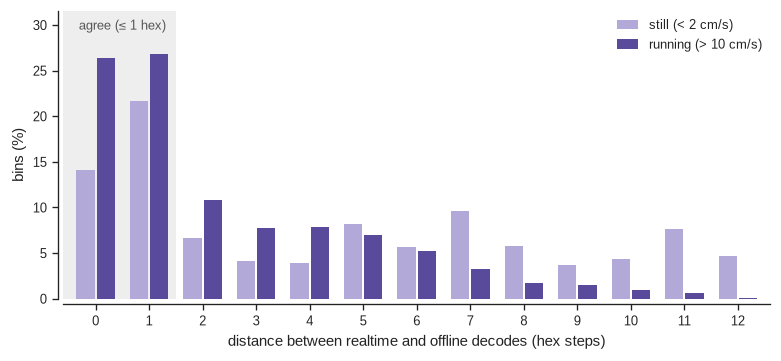

In [5]:
dis   = pairs[~pairs.agree]
known = dis[dis.of_act > 0]
overall = boot_rate(~pairs.agree, pd.Series('all', index=pairs.index)).iloc[0]
print(f'agree within {AGREE_TOL} hex : {100-overall.rate:.1f}% of bins   (exact same hex: {100*pairs.agree_exact.mean():.1f}%)')
print(f'disagree          : {overall.rate:.1f}% of bins   (95% CI {overall.lo:.1f}-{overall.hi:.1f})')
print(f'\nwhen they disagree, the decoder within {AGREE_TOL} hex of the rat is ...')
print(f'   offline  {100*known.of_err.between(0, AGREE_TOL).mean():5.1f}%')
print(f'   realtime {100*known.rt_err.between(0, AGREE_TOL).mean():5.1f}%')

steps = np.arange(0, HEXDIST.max() + 1)
fig, ax = plt.subplots(figsize=(6.4, 2.9))
ax.axvspan(-0.6, AGREE_TOL + 0.5, color=SHADE, lw=0, zorder=0)
ax.text(AGREE_TOL / 2, 0.97, f'agree (≤ {AGREE_TOL} hex)', transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=8, color=INK2)
w = 0.38
for off, (lab, sel, col) in zip([-w/2, w/2], [('still (< 2 cm/s)', pairs.still, STILL_C),
                                               ('running (> 10 cm/s)', pairs.running, RUN_C)]):
    h = pairs.d_dec[sel].value_counts(normalize=True).reindex(steps, fill_value=0)
    ax.bar(steps + off, 100 * h, width=w - 0.04, color=col, label=lab, zorder=2)
ax.set_xlim(-0.6, steps[-1] + 0.6)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)                    # headroom for the "agree" label
ax.set_xticks(steps)
ax.set_xlabel('distance between realtime and offline decodes (hex steps)')
ax.set_ylabel('bins (%)')
ax.legend(loc='upper right')
show(fig, 'fig01_decode_distance')

**Figure 1.** Distance on the maze graph between the realtime and offline decodes, for still (< 2 cm/s,
light; n = 146,134 bins) and running (> 10 cm/s, dark; n = 213,988) bins. Each distribution sums to 100%.
Shaded: distances counted as agreement (≤ 1 hex).

**Takeaway.** Under the 1-hex rule they agree on **43%** of bins (exact hex: 20%), so they disagree on **57%** (95% CI 55–59%).
When they disagree it is almost always the realtime decode that is off: offline is within a hex of the rat in 81% of
those bins, realtime in 7%. While running, the two decodes are mostly the same hex or neighbours; at rest the misses
are spread across the whole maze, out to 12 hexes away.

## 4 · What goes with disagreement — one variable at a time

**How to read the ranking.** For each variable, *AUC* is the chance that a randomly picked disagreeing bin has a
higher value than a randomly picked agreeing bin. 0.5 means the variable tells you nothing; *separation* =
|2·AUC − 1| puts it on a 0–1 scale (0 = no relation, 1 = perfectly separates agreeing from disagreeing bins). It is a
one-variable-at-a-time view: variables that move together (speed, spikes, corner) share credit here — §5 untangles them.

The figure shows the disagreement rate in bins of each variable; the dotted line is the overall rate.

,meaning,AUC,separation,higher value goes with
variable,,,,
cred_post,realtime: hexes in 50% credible set,0.726,0.452,more disagreement
post_max,realtime confidence: posterior max,0.277,0.447,less disagreement
speed,rat speed,0.383,0.234,less disagreement
spk_recent,spikes in the last 30 ms,0.437,0.125,less disagreement
corner,rat at a corner hex (1-3),0.539,0.078,more disagreement
spikes,spikes in this bin,0.466,0.068,less disagreement
of_spread,offline uncertainty (spatial_cov),0.532,0.065,more disagreement
zero_streak,zero-spike bins in a row,0.511,0.021,more disagreement
minute,minutes into the epoch,0.492,0.017,less disagreement


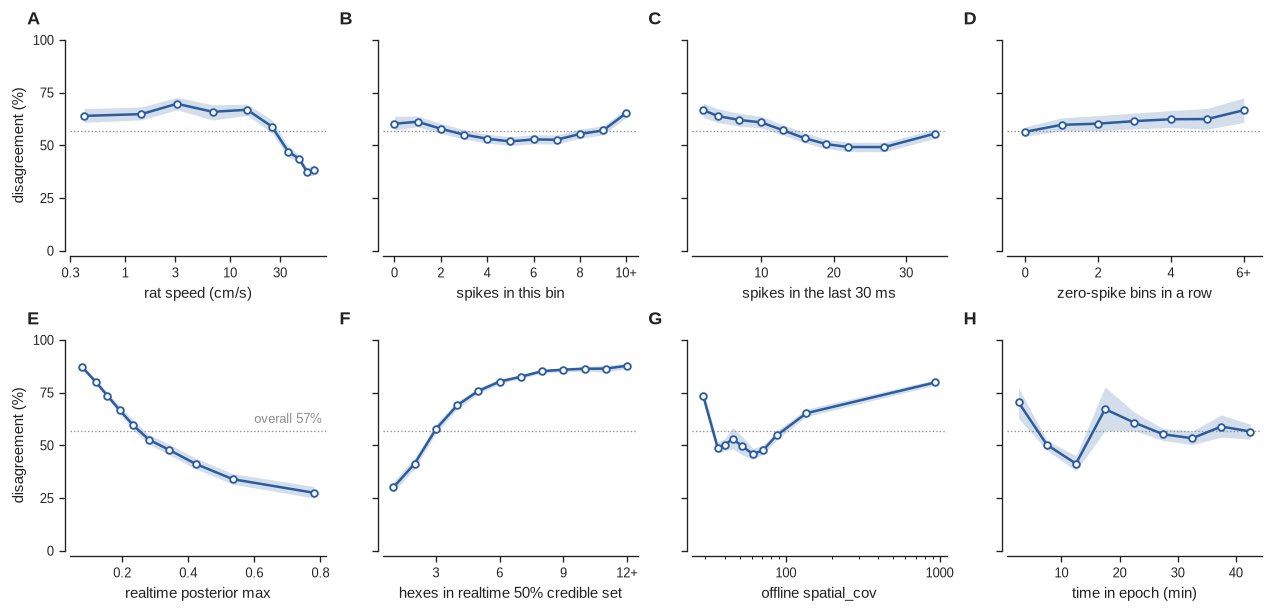

yes/no variables — disagreement rate (%) with 95% CI:


rate    lo    hi       n
        g                              
corner  False  53.1  49.5  56.7  224125
        True   60.7  58.5  63.2  233408
ripple  False  56.6  54.5  59.0  450381
        True   81.2  77.6  84.7    7152
running False  65.9  63.2  68.8  243545
        True   46.8  45.0  49.1  213988

In [6]:
def auc(x, y):
    # P(value in a random y=True bin > value in a random y=False bin); ties count half
    r = rankdata(np.asarray(x, float))
    y = np.asarray(y, bool)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

FEATURES = {
    'speed'      : 'rat speed',
    'spikes'     : 'spikes in this bin',
    'spk_recent' : 'spikes in the last 30 ms',
    'zero_streak': 'zero-spike bins in a row',
    'corner'     : 'rat at a corner hex (1-3)',
    'ripple'     : 'inside a realtime ripple',
    'of_spread'  : 'offline uncertainty (spatial_cov)',
    'minute'     : 'minutes into the epoch',
    'post_max'   : 'realtime confidence: posterior max',
    'cred_post'  : 'realtime: hexes in 50% credible set',
}
disagree = ~pairs.agree.to_numpy()
ranking = pd.DataFrame([{'variable': c, 'meaning': m, 'AUC': auc(pairs[c], disagree)} for c, m in FEATURES.items()])
ranking['separation'] = (2 * ranking.AUC - 1).abs()
ranking['higher value goes with'] = np.where(ranking.AUC > .5, 'more disagreement', 'less disagreement')
display(ranking.sort_values('separation', ascending=False).set_index('variable').round(3))

def disagree_by(col, bins=None, q=None, clip=None, df=None):
    # disagreement rate (%) with 95% CI in bins of one variable; x = median of the variable within each bin
    df = pairs if df is None else df
    x = df[col].clip(upper=clip) if clip is not None else df[col]
    key = pd.qcut(x, q, duplicates='drop') if q else (pd.cut(x, bins) if bins is not None else x)
    out = boot_rate(~df.agree, key, df)
    out['x'] = x.groupby(key, observed=True).median()
    return out[out.n >= MIN_N]

PANELS = [  # column, binning, x label
    ('speed',       dict(bins=[0, 1, 2, 5, 10, 20, 30, 40, 50, 60, 90]), 'rat speed (cm/s)'),
    ('spikes',      dict(clip=10),                                         'spikes in this bin'),
    ('spk_recent',  dict(bins=[-1, 2, 5, 8, 11, 14, 17, 20, 25, 30, 99]),  'spikes in the last 30 ms'),
    ('zero_streak', dict(clip=6),                                          'zero-spike bins in a row'),
    ('post_max',    dict(q=10),                                            'realtime posterior max'),
    ('cred_post',   dict(clip=12),                                         'hexes in realtime 50% credible set'),
    ('of_spread',   dict(q=10),                                            'offline spatial_cov'),
    ('minute',      dict(bins=np.arange(0, 50, 5)),                        'time in epoch (min)'),
]
overall_rate = 100 * disagree.mean()
fig, axes = plt.subplots(2, 4, figsize=(10.5, 5), sharey=True)
for ax, (col, kw, xl) in zip(axes.flat, PANELS):
    r = disagree_by(col, **kw)
    ax.axhline(overall_rate, color=MUTED, lw=0.8, ls=':')
    ci_line(ax, r.x, r, RT)
    ax.set_xlabel(xl)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    if col in ('speed', 'of_spread'):
        ax.set_xscale('log')
        ax.xaxis.set_major_formatter(PLAIN)
    if col == 'speed':
        ax.set_xticks([0.3, 1, 3, 10, 30], ['0.3', '1', '3', '10', '30'])
        ax.minorticks_off()
    if 'clip' in kw:                                   # the last integer bin means "this many or more"
        lo_, hi_ = int(r.x.min()), kw['clip']
        ticks = sorted({int(t) for t in mpl.ticker.MaxNLocator(5, integer=True).tick_values(lo_, hi_)
                        if lo_ <= t <= hi_} | {hi_})
        ax.set_xticks(ticks, [f'{t}+' if t == hi_ else f'{t}' for t in ticks])
        ax.set_xlim(lo_ - 0.5, hi_ + 0.5)
for ax in axes[:, 0]:
    ax.set_ylabel('disagreement (%)')
axes[1, 0].annotate(f'overall {overall_rate:.0f}%', xy=(1, overall_rate), xycoords=('axes fraction', 'data'),
                    xytext=(-2, 3), textcoords='offset points', ha='right', va='bottom', fontsize=7.5, color=MUTED)
letter(axes)
show(fig, 'fig02_disagreement_by_variable')

print('yes/no variables — disagreement rate (%) with 95% CI:')
display(pd.concat({c: boot_rate(~pairs.agree, pairs[c]) for c in ['corner', 'ripple', 'running']}).round(1))

**Figure 2.** Disagreement rate (realtime > 1 hex from offline), one variable at a time. Points: rate within
bins of the variable, plotted at the bin median; bands: 95% block-bootstrap CI; dotted line: overall rate (57%).
**A**, rat speed (log axis). **B**, spikes in the 6 ms bin. **C**, spikes in the last 30 ms. **D**, consecutive
zero-spike bins. **E**, realtime posterior maximum (deciles). **F**, hexes in the realtime 50% credible set.
**G**, offline `spatial_cov` (deciles, log axis). **H**, time in the epoch. "+" marks a bin that pools all larger
values; groups with fewer than 300 bins are omitted.

**Takeaway.**

- **The best single predictor is the realtime decoder's own confidence** (separation 0.45). When its 50% credible set
  is a single hex, disagreement is 30%; at 8 or more hexes it is ~85%.
- **Among outside variables, speed matters most** (0.23), but not as a smooth slope. Disagreement sits at 64–70% up to
  20 cm/s, then falls: 59% at 20–30, 47% at 30–40, and 37–38% above 50 cm/s.
- **Spike counts matter less** (0.13 for the last 30 ms, 0.07 for the bin itself). The in-bin curve is U-shaped:
  the busiest bins (10+ spikes) are *worse* than average, at 65% (§7 explains why).
- **Ripples:** disagreement is 81% inside ripples vs 57% overall. They rank low in the table only because they cover
  1.6% of bins.
- **Offline uncertainty** is U-shaped: disagreement is higher both when offline is extremely sharp and when it is very spread out.
- **Time in session:** the first 5 minutes are the worst (70%). That fits this being a *no-preload* run
  (`preloaded_model: false`): the encoder starts empty and learns during the epoch. The bump around minute 17 (67%)
  is not explained here.

## 5 · Untangling speed from spikes — and all variables together

Running brings more spikes and takes the rat away from the corners, so the one-at-a-time curves in §4 overlap. Two
ways to separate them:

- **The grid** holds speed fixed (columns) and varies recent spikes (rows). If spikes mattered on their own, every
  column would change the same way going up.
- **A logistic regression** fits all the variables at once. Each point is how much one standard deviation of that
  variable multiplies the odds of disagreeing *with the others held fixed* (right of 1 = more disagreement), with a
  95% block-bootstrap CI (200 refits). The fit is plain Newton's method in numpy (no sklearn / statsmodels here).

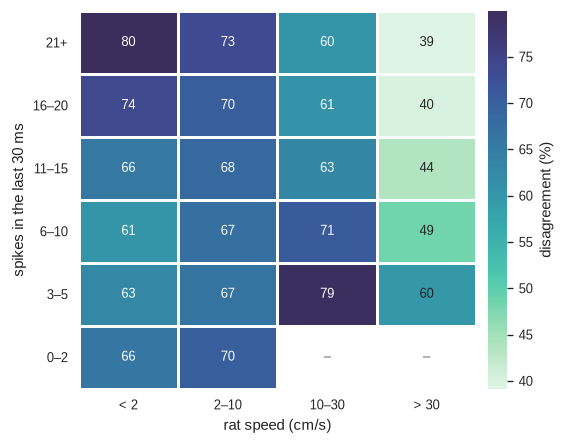

bins per cell ("–" = fewer than 300):


speed,< 2,2–10,10–30,> 30
spk_recent,,,,
0–2,15741,2902,76,32
3–5,34437,10120,867,710
6–10,55769,30621,7677,14086
11–15,25286,29544,15924,46111
16–20,8259,15180,14508,52364
21+,6642,9044,11928,49705


In [7]:
SPEED_BANDS = pd.cut(pairs.speed, [-1, 2, 10, 30, 999], labels=['< 2', '2–10', '10–30', '> 30'])
SPIKE_BANDS = pd.cut(pairs.spk_recent, [-1, 2, 5, 10, 15, 20, 999], labels=['0–2', '3–5', '6–10', '11–15', '16–20', '21+'])
grid = pairs.groupby([SPIKE_BANDS, SPEED_BANDS], observed=False).agree.agg(['mean', 'size']).unstack()
rate = 100 * (1 - grid['mean'])
n    = grid['size']
Zg   = rate.where(n >= MIN_N).to_numpy(float)

fig, ax = plt.subplots(figsize=(4.6, 3.6))
qm = ax.pcolormesh(np.ma.masked_invalid(Zg), cmap=CM_SEQ, vmin=np.nanmin(Zg), vmax=np.nanmax(Zg),
                   edgecolors='white', linewidth=1.5)
for (r_, c_), v in np.ndenumerate(Zg):
    ax.text(c_ + .5, r_ + .5, '–' if np.isnan(v) else f'{v:.0f}', ha='center', va='center',
            fontsize=8, color=text_on(CM_SEQ(qm.norm(v))) if np.isfinite(v) else INK2)
ax.set_xticks(np.arange(Zg.shape[1]) + .5, rate.columns)
ax.set_yticks(np.arange(Zg.shape[0]) + .5, rate.index)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel('rat speed (cm/s)')
ax.set_ylabel('spikes in the last 30 ms')
cb = fig.colorbar(qm, ax=ax, fraction=.05, pad=.03)
cb.outline.set_visible(False)
cb.set_label('disagreement (%)')
show(fig, 'fig03_speed_by_spikes')
print(f'bins per cell ("–" = fewer than {MIN_N}):')
display(n)

,odds ratio per SD,CI low,CI high,with realtime confidence added
speed (log),0.505,0.460,0.544,0.482
at a corner,0.809,0.727,0.889,0.912
spikes in previous 24 ms,0.922,0.894,0.947,1.027
zero-spike streak,0.950,0.933,0.971,0.835
time in epoch,0.992,0.915,1.091,0.928
spikes in this bin,1.027,1.018,1.038,1.649
inside ripple,1.111,1.075,1.148,1.142
offline spread (log),1.596,1.531,1.659,1.446


realtime confidence itself (posterior max), per SD: odds x0.34

how well each model separates disagreeing from agreeing bins (AUC, 0.5 = chance):
   speed alone                        0.617
   recent spikes alone                0.563
   all behaviour + spike variables    0.670
   ... + realtime confidence          0.776


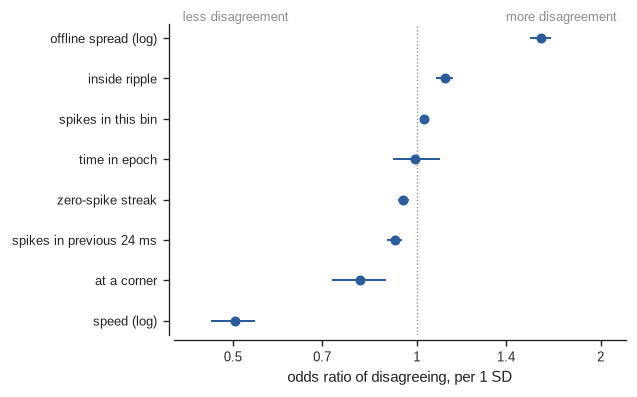

In [8]:
def fit_logit(X, y, w=None, b0=None, iters=30):
    # (weighted) logistic regression by Newton's method; X is standardised, an intercept is added
    X1 = np.c_[np.ones(len(X)), X]
    w  = np.ones(len(y)) if w is None else w
    b  = np.zeros(X1.shape[1]) if b0 is None else b0.copy()
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X1 @ b))
        step = np.linalg.solve(X1.T @ (X1 * (w * p * (1 - p))[:, None]), X1.T @ (w * (y - p)))
        b += step
        if np.abs(step).max() < 1e-7:
            break
    return b, 1 / (1 + np.exp(-X1 @ b))

design = pd.DataFrame({
    'speed (log)'             : np.log1p(pairs.speed),
    'at a corner'             : pairs.corner.astype(float),
    'spikes in this bin'      : pairs.spikes,
    'spikes in previous 24 ms': pairs.spk_recent - pairs.spikes,
    'zero-spike streak'       : pairs.zero_streak.clip(upper=6),
    'inside ripple'           : pairs.ripple.astype(float),
    'offline spread (log)'    : np.log(pairs.of_spread),
    'time in epoch'           : pairs.minute,
})
Z = ((design - design.mean()) / design.std()).to_numpy()
y = disagree.astype(float)

b_ext, p_ext = fit_logit(Z, y)                                                  # behaviour + spike supply
conf = ((pairs.post_max - pairs.post_max.mean()) / pairs.post_max.std()).to_numpy()
b_all, p_all = fit_logit(np.c_[Z, conf], y)                                     # ... + realtime confidence

blk  = pairs.block.to_numpy()
boot = np.array([fit_logit(Z, y, w=BOOT_W[r][blk], b0=b_ext)[0][1:] for r in range(200)])
coef = pd.DataFrame({'odds ratio per SD': np.exp(b_ext[1:]),
                     'CI low' : np.exp(np.percentile(boot, 2.5, axis=0)),
                     'CI high': np.exp(np.percentile(boot, 97.5, axis=0)),
                     'with realtime confidence added': np.exp(b_all[1:-1])}, index=design.columns)
coef = coef.sort_values('odds ratio per SD')
display(coef.round(3))
print(f'realtime confidence itself (posterior max), per SD: odds x{np.exp(b_all[-1]):.2f}')

print('\nhow well each model separates disagreeing from agreeing bins (AUC, 0.5 = chance):')
for lab, s in [('speed alone', pairs.speed), ('recent spikes alone', pairs.spk_recent),
               ('all behaviour + spike variables', p_ext), ('... + realtime confidence', p_all)]:
    a = auc(s, disagree)
    print(f'   {lab:34s} {max(a, 1 - a):.3f}')

fig, ax = plt.subplots(figsize=(5.2, 3.2))
yy = np.arange(len(coef))
ax.axvline(1, color=MUTED, lw=0.8, ls=':')
ax.errorbar(coef['odds ratio per SD'], yy, xerr=[coef['odds ratio per SD'] - coef['CI low'],
                                                 coef['CI high'] - coef['odds ratio per SD']],
            fmt='o', color=RT, mfc=RT, ms=5, elinewidth=1.2, capsize=0)
ax.set_yticks(yy, coef.index)
ax.set_xscale('log')
ax.set_xticks([0.5, 0.7, 1, 1.4, 2], ['0.5', '0.7', '1', '1.4', '2'])
ax.minorticks_off()
ax.set_xlim(0.4, 2.2)
ax.set_xlabel('odds ratio of disagreeing, per 1 SD')
ax.annotate('less disagreement', xy=(0.02, 1.0), xycoords='axes fraction', ha='left', va='bottom', fontsize=7.5, color=MUTED)
ax.annotate('more disagreement', xy=(0.98, 1.0), xycoords='axes fraction', ha='right', va='bottom', fontsize=7.5, color=MUTED)
show(fig, 'fig04_logistic_regression')

**Figure 3.** Disagreement rate (%) by speed band (columns) and spikes in the last 30 ms (rows).
"–": fewer than 300 bins.

**Figure 4.** Logistic regression of disagreement on all behaviour and spike-supply variables at once. Points:
odds ratio per 1 SD of each variable, with the others held fixed; whiskers: 95% block-bootstrap CI (200 refits);
dotted line: no effect.

**Takeaway.**

- **Spikes only help while the rat runs fast.** Above 30 cm/s, going from 3–5 to 21+ recent spikes cuts disagreement
  from 60% to 39%. At rest it goes the other way: 61% at 6–10 spikes, 80% at 21+.
- **With everything in one model, speed is the largest effect** (odds of disagreeing ×0.51 per SD of log speed,
  95% CI 0.46–0.54), then **offline's own uncertainty** (×1.60, 1.53–1.66). When the smoother itself is unsure they disagree more, which is
  partly about offline rather than realtime. Spike counts, empty-bin streaks and time in session each move the odds by
  less than 10% per SD.
- **The corner effect flips once speed is in the model** (×0.81, 0.73–0.89): at the same speed, being at a corner
  goes with slightly *less* disagreement. Corners look bad because the rat is *still* there, not because of the
  place itself (A6 checks this directly).
- **Behaviour and spikes together explain only a little** (AUC 0.67; speed alone 0.62). Adding the realtime
  decoder's own confidence lifts it to 0.78. The decoder "knows" when it is unreliable better than behaviour
  predicts, and that is what makes gating (§11) work.

## 6 · When they disagree, how many of those bins had no or very few spikes?

Counted two ways. **In the bin itself** is the literal answer. **In the last 30 ms** is the fairer one: the realtime
posterior is recursive, so spikes from the previous few bins are still shaping it — a bin with zero spikes of its
own is not necessarily a bin without evidence.

,% of disagreeing bins,% of agreeing bins,disagreement rate in those bins %,n bins
condition,,,,
0 spikes in the bin,16.7,14.6,60.2,72390
<=1 spike in the bin,37.1,31.8,60.7,159386
<=2 spikes in the bin,55.8,49.8,59.7,243563
0 spikes in the last 30 ms,0.7,0.5,64.8,2809
<=2 spikes in the last 30 ms,4.8,3.2,66.7,18751
<=5 spikes in the last 30 ms,16.1,11.6,64.7,64885


disagreement overall              : 57.0%
disagreement in bins with >=1 spike: 56.4%  -> dropping every zero-spike bin would barely change the picture


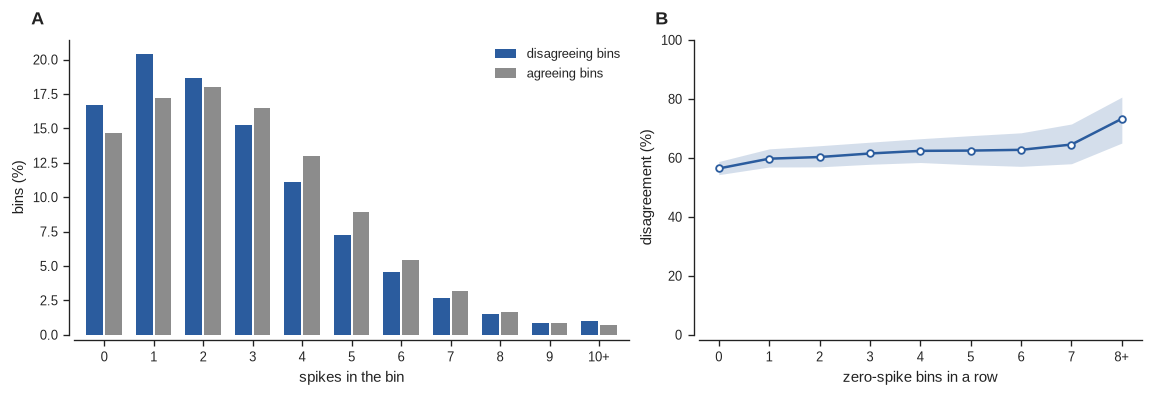

exact-hex disagreement by zero-spike streak (4 = 4+): {0: 78.6, 1: 84.8, 2: 94.4, 3: 99.3, 4: 99.9}
bins per streak length: {0: 385143, 1: 48388, 2: 13561, 3: 5164, 4: 2468, 5: 1217, 6: 665, 7: 400, 8: 527}


In [9]:
D, A = pairs[~pairs.agree], pairs[pairs.agree]
checks = [('0 spikes in the bin',          'spikes',     0),
          ('<=1 spike in the bin',         'spikes',     1),
          ('<=2 spikes in the bin',        'spikes',     2),
          ('0 spikes in the last 30 ms',   'spk_recent', 0),
          ('<=2 spikes in the last 30 ms', 'spk_recent', 2),
          ('<=5 spikes in the last 30 ms', 'spk_recent', 5)]
spike_tab = pd.DataFrame([{
    'condition'                   : lab,
    '% of disagreeing bins'       : 100 * (D[c] <= k).mean(),
    '% of agreeing bins'          : 100 * (A[c] <= k).mean(),
    'disagreement rate in those bins %': 100 * (1 - pairs.agree[pairs[c] <= k].mean()),
    'n bins'                      : int((pairs[c] <= k).sum()),
} for lab, c, k in checks]).set_index('condition')
display(spike_tab.round(1))

print(f'disagreement overall              : {100*(~pairs.agree).mean():.1f}%')
print(f'disagreement in bins with >=1 spike: {100*(~pairs.agree[pairs.spikes > 0]).mean():.1f}%  '
      f'-> dropping every zero-spike bin would barely change the picture')

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.2), width_ratios=[1.25, 1])
ks = np.arange(0, 11)
w = 0.38
for off, (lab, df, col) in zip([-w/2, w/2], [('disagreeing bins', D, RT), ('agreeing bins', A, MUTED)]):
    h = df.spikes.clip(upper=10).value_counts(normalize=True).reindex(ks, fill_value=0)
    a0.bar(ks + off, 100 * h, width=w - 0.04, color=col, label=lab)
a0.set_xticks(ks, [*map(str, ks[:-1]), '10+'])
a0.set_xlim(-0.6, 10.6)
a0.set_xlabel('spikes in the bin')
a0.set_ylabel('bins (%)')
a0.legend(loc='upper right')

r = disagree_by('zero_streak', clip=8)
ci_line(a1, r.x, r, RT)
a1.set_xticks(r.x, [*map(str, r.x.astype(int)[:-1]), f'{int(r.x.iloc[-1])}+'])
a1.set_ylim(0, 100)
a1.set_xlabel('zero-spike bins in a row')
a1.set_ylabel('disagreement (%)')
letter([a0, a1])
show(fig, 'fig05_spike_content')

# the same streaks scored by exact hex: during empty bins the decode slides to a neighbour, which the 1-hex rule forgives
ex = pairs.groupby(pairs.zero_streak.clip(upper=4)).agree_exact.agg(lambda s: 100 * (1 - s.mean()))
print('exact-hex disagreement by zero-spike streak (4 = 4+):', ex.round(1).to_dict())
print('bins per streak length:', r.n.astype(int).to_dict())

**Figure 5.** **A**, Spike count per 6 ms bin in disagreeing (blue) and agreeing (grey) bins; each
distribution sums to 100%. **B**, Disagreement rate by the number of consecutive zero-spike bins ending at that bin;
band: 95% CI.

**Answer.** Of the bins where they disagree:

- **16.7% had zero spikes** in the bin, **37% had ≤ 1**, **56% had ≤ 2**.
- But agreeing bins look almost the same (14.6%, 32%, 50%), and disagreement in zero-spike bins (60%) is barely above
  the overall 57%. Dropping every zero-spike bin would only move disagreement from 57.0% to 56.4%.
- Counting the last 30 ms instead (what the recursive posterior still carries), **only 0.7% of disagreeing bins had no
  spikes at all**, and 4.8% had ≤ 2.

So a lack of spikes is **not** why they disagree. One nuance: scored by *exact* hex, a run of 3 or more empty bins is
a near-certain miss (99%), but under the 1-hex rule it is only ~62%. During empty bins the decode slides to a
neighbouring hex rather than jumping away.

## 7 · At rest, more spikes means *more* disagreement — is that replay?

When the rat is still, bursts of spikes often come with sharp-wave ripples, and the content decoded then can be
**non-local** (far from the rat). The offline smoother and the causal realtime decoder could easily handle those
moments differently. Here, among still bins only:

- *non-local* = the decode is ≥ 2 hex steps from the rat's true hex;
- *ripple* = inside a consensus ripple from the realtime ripple detector.

disagree             inside a ripple             offline non-local  \
          rate    lo    hi            rate    lo    hi              rate   
g                                                                          
0–2       66.0  62.8  69.2             0.1   0.0   0.1              16.7   
3–5       62.8  59.6  66.2             0.4   0.2   0.5              12.9   
6–10      60.7  57.5  64.0             0.8   0.5   1.2              10.1   
11–15     65.5  62.4  68.7             2.6   1.7   3.6              11.9   
16–20     73.9  71.1  76.9             6.6   3.7  10.2              19.0   
21–25     78.6  76.3  81.3            13.5   7.0  20.8              28.4   
26+       81.1  77.2  85.1            22.6  12.8  34.6              53.9   

                  realtime non-local               bins  
         lo    hi               rate    lo    hi      n  
g                                                        
0–2    12.0  22.9               69.0  65.8  72.0  15741  
3–5     9.7  16.9               65.0  61.9  68.5  34436  
6–10    7.9  12.8               61.6  58.5  65.1  55760  
11–15   9.3  14.9               65.6  62.6  69.1  25279  
16–20  14.2  23.6               73.1  70.5  76.0   8259  
21–25  23.6  32.8               79.0  75.5  82.8   3058  
26+    47.0  61.5               90.5  84.2  96.1   3584

still bins, inside vs outside ripples:


,n,disagree_pct,offline_nonlocal_pct,realtime_nonlocal_pct,mean_recent_spikes
ripple,,,,,
False,143119,63.85,13.46,65.29,8.35
True,2998,81.19,28.35,80.79,20.37


when offline itself decodes non-local content at rest (n=20,109), realtime agrees with it 22.0% of the time (vs 35.8% over all still bins)


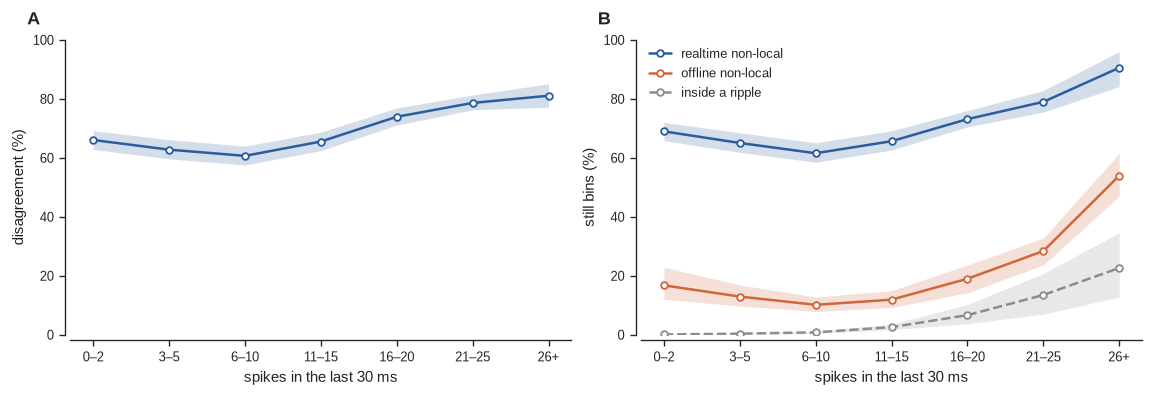

In [10]:
st = pairs[pairs.still & (pairs.of_act > 0)].copy()
st['band'] = pd.cut(st.spk_recent, [-1, 2, 5, 10, 15, 20, 25, 999],
                    labels=['0–2', '3–5', '6–10', '11–15', '16–20', '21–25', '26+'])
R = {name: boot_rate(ev, st.band, st) for name, ev in [
        ('disagree',           ~st.agree),
        ('inside a ripple',    st.ripple),
        ('offline non-local',  st.of_err >= 2),
        ('realtime non-local', st.rt_err >= 2)]}
rest_tab = pd.concat({k_: v[['rate', 'lo', 'hi']] for k_, v in R.items()}, axis=1)
rest_tab[('bins', 'n')] = R['disagree'].n
display(rest_tab.round(1))

print('still bins, inside vs outside ripples:')
display(st.groupby('ripple').agg(
    n                    =('agree', 'size'),
    disagree_pct         =('agree', lambda s: 100 * (1 - s.mean())),
    offline_nonlocal_pct =('of_err', lambda s: 100 * (s >= 2).mean()),
    realtime_nonlocal_pct=('rt_err', lambda s: 100 * (s >= 2).mean()),
    mean_recent_spikes   =('spk_recent', 'mean')).round(2))

nl = st[st.of_err >= 2]
print(f'when offline itself decodes non-local content at rest (n={len(nl):,}), realtime agrees with it '
      f'{100*nl.agree.mean():.1f}% of the time (vs {100*st.agree.mean():.1f}% over all still bins)')

x = np.arange(len(R['disagree']))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.2), sharex=True)
ci_line(a0, x, R['disagree'], RT)
a0.set_ylabel('disagreement (%)')
for lab, c, ls in [('realtime non-local', RT, '-'), ('offline non-local', OF, '-'), ('inside a ripple', MUTED, '--')]:
    ci_line(a1, x, R[lab], c, label=lab, ls=ls)
a1.set_ylabel('still bins (%)')
a1.legend(loc='upper left')
for ax in (a0, a1):
    ax.set_ylim(0, 100)
    ax.set_xticks(x, R['disagree'].index)
    ax.set_xlabel('spikes in the last 30 ms')
letter([a0, a1])
show(fig, 'fig06_rest_high_spike')

**Figure 6.** Still bins only (< 2 cm/s), by spikes in the last 30 ms. **A**, Disagreement rate.
**B**, Share of still bins in which the realtime decode (blue) or the offline decode (orange) is ≥ 2 hexes from the
rat, and share inside a consensus ripple (grey, dashed). Bands: 95% CI.

**Takeaway.** Partly, yes. At rest the high-spike bins are increasingly replay-like: with 26+ spikes in
30 ms, 23% are inside a ripple and offline decodes non-local content in 54% of them, against 10–17% for ordinary rest
bins. Disagreement climbs with them, to 81%.

The realtime decoder's "non-local" decodes can't be read the same way, though. It is non-local in 62–69% of
*ordinary* rest bins too, because at rest it rarely names the rat's own hex at all (the corner blind spot, A6). And
when offline does decode non-local content at rest, realtime agrees only 22% of the time, worse than on rest bins
overall (36%). So realtime's non-local decodes at rest are mostly not the replay content offline sees.

## 8 · Flickers or sustained? Disagreement episodes

For closed-loop use, a 6 ms flicker matters much less than a decode that stays wrong for a second. An *episode* is
a run of consecutive disagreeing bins. Panel A answers: *what share of all disagreeing time sits in episodes at
least this long?* Panel B compares how often each label changes hex.

31,319 disagreement episodes   median 12 ms   longest 5.3 s
   share of disagreeing time in episodes >=  100 ms:  66.8%
   share of disagreeing time in episodes >=  500 ms:  23.7%
   share of disagreeing time in episodes >= 1000 ms:   8.0%

what the episodes look like, by length (bin-weighted means):


,episodes,% of disagree time,mean speed cm/s,% still,% at a corner,spikes / 30 ms
length,,,,,,
<30 ms,23173.0,16.3,25.3,25.3,39.5,14.2
30-100 ms,4596.0,16.8,22.3,26.2,37.0,14.3
0.1-1 s,3472.0,58.8,13.2,39.6,59.5,12.5
>1 s,78.0,8.0,5.5,52.2,84.0,10.3


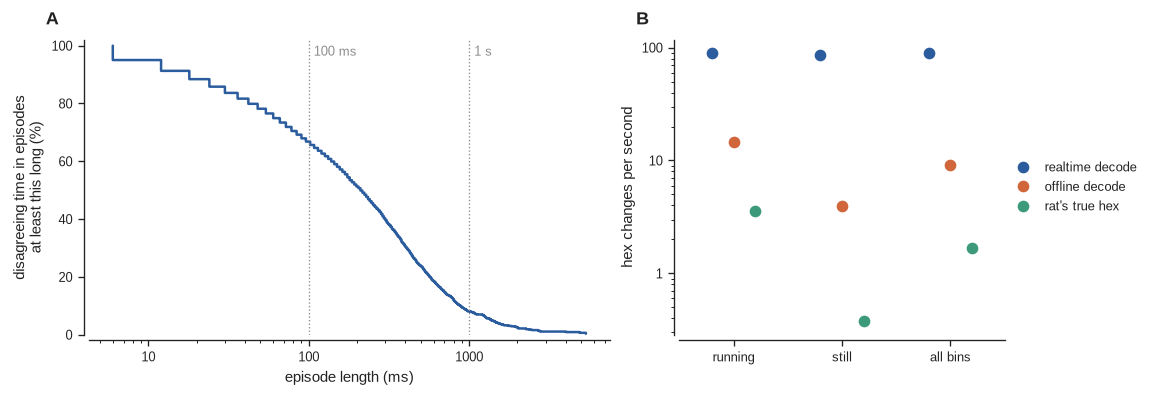

,running,still,all bins
realtime decode,89.0,86.4,89.1
offline decode,14.7,3.9,9.2
rat's true hex,3.6,0.4,1.7


In [11]:
x = np.r_[0, (~pairs.agree).to_numpy().astype(int), 0]
edges = np.flatnonzero(np.diff(x))
ep = pd.DataFrame({'start': edges[::2], 'stop': edges[1::2]})
ep['dur_ms'] = (ep.stop - ep.start) * BIN_S * 1e3
for col in ['speed', 'spk_recent', 'corner', 'still']:
    v = np.r_[0, np.cumsum(pairs[col].to_numpy(float))]
    ep[col] = (v[ep.stop] - v[ep.start]) / (ep.stop - ep.start)       # episode mean

total = ep.dur_ms.sum()
print(f'{len(ep):,} disagreement episodes   median {ep.dur_ms.median():.0f} ms   longest {ep.dur_ms.max()/1e3:.1f} s')
for L in [100, 500, 1000]:
    print(f'   share of disagreeing time in episodes >= {L:4d} ms: {100*ep.dur_ms[ep.dur_ms >= L].sum()/total:5.1f}%')

ep['length'] = pd.cut(ep.dur_ms, [0, 30, 100, 1000, 1e9], labels=['<30 ms', '30-100 ms', '0.1-1 s', '>1 s'])
print('\nwhat the episodes look like, by length (bin-weighted means):')
display(ep.groupby('length', observed=True).apply(lambda g: pd.Series({
    'episodes'          : len(g),
    '% of disagree time': 100 * g.dur_ms.sum() / total,
    'mean speed cm/s'   : np.average(g.speed, weights=g.dur_ms),
    '% still'           : 100 * np.average(g.still, weights=g.dur_ms),
    '% at a corner'     : 100 * np.average(g.corner, weights=g.dur_ms),
    'spikes / 30 ms'    : np.average(g.spk_recent, weights=g.dur_ms),
}), include_groups=False).round(1))

def switches_per_s(h):
    return (np.diff(np.asarray(h)) != 0).mean() / BIN_S
SW = pd.DataFrame({sel: {'realtime decode': switches_per_s(pairs.rt_dec[m]),
                         'offline decode' : switches_per_s(pairs.of_dec[m]),
                         "rat's true hex" : switches_per_s(pairs.of_act[m])}
                   for sel, m in [('running', pairs.running), ('still', pairs.still), ('all bins', slice(None))]})

d = np.sort(ep.dur_ms.to_numpy())
share_at_least = 1 - np.r_[0, np.cumsum(d)[:-1]] / total
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.2), width_ratios=[1.6, 1])
a0.step(d, 100 * share_at_least, where='post', color=RT)
for L, lab in [(100, '100 ms'), (1000, '1 s')]:
    a0.axvline(L, color=MUTED, lw=0.8, ls=':')
    a0.annotate(lab, (L, 100), xytext=(3, 0), textcoords='offset points', fontsize=7.5, color=MUTED, va='top')
a0.set_xscale('log')
a0.xaxis.set_major_formatter(PLAIN)
a0.set_ylim(0, 102)
a0.set_xlabel('episode length (ms)')
a0.set_ylabel('disagreeing time in episodes\nat least this long (%)')

xs = np.arange(SW.shape[1])
for k_, (lab, c) in enumerate([('realtime decode', RT), ('offline decode', OF), ("rat's true hex", TRUE)]):
    a1.plot(xs + (k_ - 1) * 0.2, SW.loc[lab], ls='none', marker='o', ms=6, color=c, label=lab)
a1.set_yscale('log')
a1.yaxis.set_major_formatter(PLAIN)
a1.set_xticks(xs, SW.columns)
a1.set_xlim(-0.5, len(xs) - 0.5)
a1.set_ylabel('hex changes per second')
a1.legend(loc='center left', bbox_to_anchor=(1, 0.5))
letter([a0, a1])
show(fig, 'fig07_episodes_and_jitter')
display(SW.round(1))

**Figure 7.** **A**, Share of all disagreeing time spent in disagreement episodes at least as long as the x
value. **B**, How often each label changes hex, per second (log axis), for running, still and all bins.

**Takeaway.** Most disagreements are short (the median episode is 12 ms, two bins), but the long ones hold
most of the time: **67% of disagreeing time is in episodes of 100 ms or more**, and 8% in episodes over a second
(longest 5.3 s). The long episodes are rest at the corners: episodes over 1 s are 84% at a corner, mean speed 5.5 cm/s.

Separately, the realtime decode **changes hex 89 times per second, whether the rat runs or rests**. That is 10× the
offline decode (9/s) and 50× the rat (1.7/s), and it is the clearest sign that the prior is too loose (§14).

## 9 · Where on the maze do they disagree?

Disagreement rate by the **rat's true hex**, split by behaviour so that location isn't just standing in for speed.
Grey hexes had fewer than `MIN_N` bins in that state.

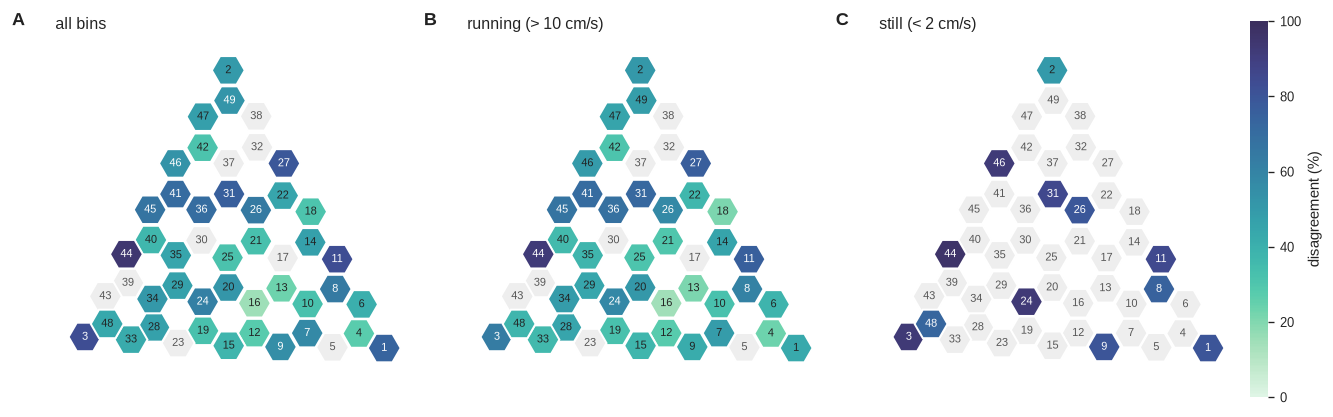

the 12 hexes where the rat spends the most time (NaN = fewer than MIN_N bins):


,% of time,% still,disagree %,disagree running %,disagree still %
of_act,,,,,
2,29.0,60.5,49.8,50.5,49.9
1,19.2,53.0,73.9,43.0,80.1
11,4.3,27.9,83.1,75.8,85.2
26,3.1,23.6,64.4,57.1,79.1
3,2.9,29.5,83.1,63.6,92.9
46,2.4,6.1,52.7,49.2,92.6
49,2.3,2.7,52.1,48.2,NaN
24,2.2,4.1,61.3,57.6,92.6
47,2.0,0.9,47.7,45.6,NaN


In [12]:
cen = pd.read_csv(cfg['encoder']['position']['hex_centroid_file']).set_index('hex').reindex(HEX_IDS)
XY  = cen[['x', 'y']].to_numpy(float)
dd  = np.hypot(*(XY[:, None, :] - XY[None, :, :]).T)
np.fill_diagonal(dd, np.inf)
NN  = float(np.median(dd.min(axis=1)))                      # centre-to-centre spacing of neighbours
nbr = np.argmin(dd, axis=1)
ang = np.degrees(np.arctan2(XY[nbr, 1] - XY[:, 1], XY[nbr, 0] - XY[:, 0])) % 60
ORIENT = 0.0 if np.mean(np.minimum(ang, 60 - ang) < 15) > 0.5 else np.pi / 6
R_HEX = NN / np.sqrt(3) * 0.96

def draw_hex_map(ax, values, n, title, vmin=0, vmax=100):
    # values, n: Series indexed by hex id; hexes with n < MIN_N are drawn grey
    norm = mpl.colors.Normalize(vmin, vmax)
    for h, (x_, y_) in zip(HEX_IDS, XY):
        v, shown = values.get(h, np.nan), n.get(h, 0) >= MIN_N
        face = CM_SEQ(norm(v)) if shown and np.isfinite(v) else SHADE
        ax.add_patch(RegularPolygon((x_, y_), 6, radius=R_HEX, orientation=ORIENT,
                                    facecolor=face, edgecolor='white', linewidth=1.2))
        ax.text(x_, y_, str(h), ha='center', va='center', fontsize=6.5,
                color=text_on(face) if face is not SHADE else INK2)
    ax.set_xlim(XY[:, 0].min() - NN, XY[:, 0].max() + NN)
    ax.set_ylim(XY[:, 1].max() + NN, XY[:, 1].min() - NN)     # image coordinates: y grows downward
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title)
    return mpl.cm.ScalarMappable(norm=norm, cmap=CM_SEQ)

known = pairs[pairs.of_act > 0]
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (lab, sel) in zip(axes, [('all bins', slice(None)), ('running (> 10 cm/s)', known.running),
                                 ('still (< 2 cm/s)', known.still)]):
    g = known[sel].groupby('of_act').agree
    sm = draw_hex_map(ax, 100 * (1 - g.mean()), g.size(), lab)
cb = fig.colorbar(sm, ax=axes, fraction=.02, pad=.01, shrink=.8)
cb.outline.set_visible(False)
cb.set_label('disagreement (%)')
letter(axes)
show(fig, 'fig08_hex_map')

def pct_dis(s):
    return 100 * (1 - s.mean()) if len(s) >= MIN_N else np.nan
by_hex = pd.DataFrame({
    '% of time'          : 100 * known.of_act.value_counts(normalize=True),
    '% still'            : 100 * known.groupby('of_act').still.mean(),
    'disagree %'         : known.groupby('of_act').agree.agg(pct_dis),
    'disagree running %' : known[known.running].groupby('of_act').agree.agg(pct_dis),
    'disagree still %'   : known[known.still].groupby('of_act').agree.agg(pct_dis),
})
print('the 12 hexes where the rat spends the most time (NaN = fewer than MIN_N bins):')
display(by_hex.sort_values('% of time', ascending=False).head(12).round(1))

**Figure 8.** Disagreement rate by the rat's true hex, for **A**, all bins, **B**, running bins and
**C**, still bins. Hexes are drawn at their tracked centroids (camera coordinates). Grey: fewer than 300 bins in
that state.

**Takeaway.** The corner problem is mostly hexes **1 and 3**. At rest, realtime disagrees 80% of the time
at hex 1 and 93% at hex 3, but only 50% at hex 2, where the rat spends the most time. Running through hex 1 is fine
(43%, better than the 47% running average). A few hexes are bad even while running (hex 11: 76%, hex 3: 64%), and
hex 4 is the best of the often-visited hexes (23% while running).

## 10 · Soft agreement — beyond the single best hex

The argmax throws away the rest of the realtime posterior. These scores ask how much realtime belief sits on (or
next to) the hex offline picked:

- **probability on offline's hex** — realtime posterior mass on exactly that hex;
- **probability within `AGREE_TOL` hex** — mass on offline's hex and its neighbours (the soft version of `agree`);
- **inside the 50% credible set** — offline's hex is among the fewest realtime hexes that together hold 50% of the posterior.

**Baseline:** the same scores after shifting the offline decode by half the epoch. That keeps both decoders' own
habits (e.g. favourite hexes) but breaks the moment-to-moment link, so it is the "no shared information" level.

,actual,time-shifted baseline,running,still
mean realtime probability on offline's hex,0.148,0.033,0.180,0.124
mean realtime probability within 1 hex of it,0.319,0.085,0.420,0.231
offline's hex inside realtime 50% credible set (%),39.297,9.663,47.003,34.739
realtime argmax within 1 hex (%),43.007,10.140,53.190,35.795


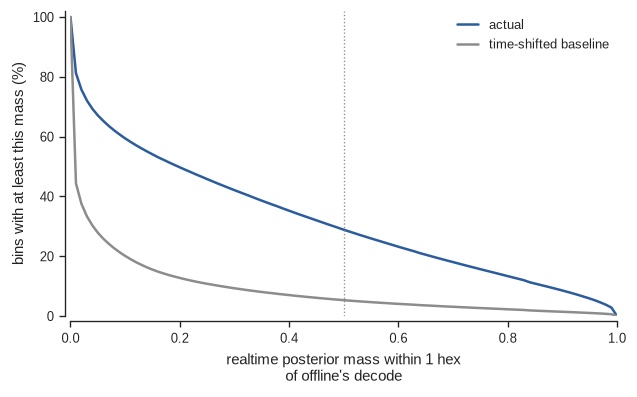

at least half the realtime mass near offline's hex: 28.9% of bins (baseline 5.3%)


In [13]:
P    = POST[ROWS]
NEAR = (HEXDIST[1:NH, 1:NH] >= 0) & (HEXDIST[1:NH, 1:NH] <= AGREE_TOL)   # NEAR[a, b]: hex a+1 within tol of hex b+1

def soft_scores(of_hex):
    c = np.asarray(of_hex) - 1
    p_at   = P[np.arange(len(c)), c]
    p_near = (P * NEAR[c]).sum(1)
    in_cs  = np.where(P > p_at[:, None], P, 0).sum(1) < 0.5     # mass strictly above it is < 50%
    argmax_near = hex_steps(pairs.rt_dec, np.asarray(of_hex)).clip(0) <= AGREE_TOL
    return pd.DataFrame({'p_at': p_at, 'p_near': p_near, 'in_cs': in_cs, 'argmax_near': argmax_near})

real  = soft_scores(pairs.of_dec)
shift = soft_scores(np.roll(pairs.of_dec.to_numpy(), len(pairs) // 2))
labels = {'p_at': "mean realtime probability on offline's hex",
          'p_near': f'mean realtime probability within {AGREE_TOL} hex of it',
          'in_cs': "offline's hex inside realtime 50% credible set (%)",
          'argmax_near': f'realtime argmax within {AGREE_TOL} hex (%)'}
soft = pd.DataFrame({'actual': real.mean(), 'time-shifted baseline': shift.mean(),
                     'running': real[pairs.running.to_numpy()].mean(),
                     'still': real[pairs.still.to_numpy()].mean()})
soft.loc[['in_cs', 'argmax_near']] *= 100
display(soft.rename(index=labels).round(3))

grid_x = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for lab, s, col in [('actual', real.p_near, RT), ('time-shifted baseline', shift.p_near, MUTED)]:
    srt = np.sort(s.to_numpy())
    ax.plot(grid_x, 100 * (1 - np.searchsorted(srt, grid_x, side='left') / len(srt)), color=col, label=lab)
ax.axvline(0.5, color=MUTED, lw=0.8, ls=':')
ax.set_xlim(0, 1)
ax.set_ylim(0, 102)
ax.set_xlabel(f"realtime posterior mass within {AGREE_TOL} hex\nof offline's decode")
ax.set_ylabel('bins with at least this mass (%)')
ax.legend(loc='upper right')
show(fig, 'fig09_soft_agreement')
print(f"at least half the realtime mass near offline's hex: {100*(real.p_near >= .5).mean():.1f}% of bins "
      f"(baseline {100*(shift.p_near >= .5).mean():.1f}%)")

**Figure 9.** Share of bins in which the realtime posterior puts at least the x-axis amount of probability
within 1 hex of the offline decode (blue), against a time-shifted baseline (grey; the offline decode shifted by half
the epoch). Dotted line: half the posterior mass.

**Takeaway.** The realtime posterior carries real information about offline's answer even when its argmax
misses. On average it puts 32% of its probability within a hex of offline's decode, about 4× the time-shifted
baseline (8.5%), and offline's hex is inside realtime's 50% credible set 39% of the time (baseline 10%). But that
belief is spread thin: at least half of it lands near offline in only 29% of bins. Running is better than rest (42%
vs 23% of the mass nearby).

## 11 · Confidence gating — trust only the confident bins?

If the closed loop acted only on bins where the realtime posterior peak is high, how much agreement would it get, and
how many bins would it give up? The x-axis keeps the most confident X% of bins (below 1% the curve rests on too few
bins to show). Because confidence is higher while running, the table also shows how the kept bins split between
running and still.

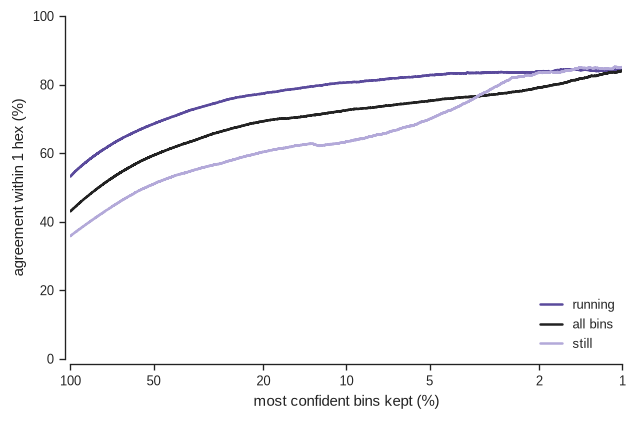

,posterior max >=,agree %,exact agree %,% running,% still
keep top %,,,,,
100,0.026,43.007,19.756,46.770,31.940
50,0.257,59.354,31.406,54.809,26.103
25,0.422,67.532,40.400,56.491,25.057
10,0.627,72.524,49.533,54.528,26.025
5,0.780,75.210,57.243,45.825,32.348


In [14]:
def gating_curve(df):
    o = np.argsort(-df.post_max.to_numpy(), kind='stable')
    a = df.agree.to_numpy()[o]
    keep = np.arange(1, len(a) + 1)
    return keep / len(a) * 100, np.cumsum(a) / keep * 100, df.post_max.to_numpy()[o]

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for lab, df, col in [('running', pairs[pairs.running], RUN_C), ('all bins', pairs, INK), ('still', pairs[pairs.still], STILL_C)]:
    kept, agr, _ = gating_curve(df)
    ax.plot(kept, agr, color=col, label=lab)
ax.set_xscale('log')
ax.set_xlim(100, 1)
ax.set_xticks([100, 50, 20, 10, 5, 2, 1], ['100', '50', '20', '10', '5', '2', '1'])
ax.minorticks_off()
ax.set_ylim(0, 100)
ax.set_xlabel('most confident bins kept (%)')
ax.set_ylabel(f'agreement within {AGREE_TOL} hex (%)')
ax.legend(loc='lower right')
show(fig, 'fig10_confidence_gating')

kept, agr, thr = gating_curve(pairs)
o = np.argsort(-pairs.post_max.to_numpy(), kind='stable')
rows = []
for pct in [100, 50, 25, 10, 5]:
    k_ = int(len(o) * pct / 100)
    sel = pairs.iloc[o[:k_]]
    rows.append({'keep top %': pct, 'posterior max >=': thr[k_ - 1], 'agree %': agr[k_ - 1],
                 'exact agree %': 100 * sel.agree_exact.mean(),
                 '% running': 100 * sel.running.mean(), '% still': 100 * sel.still.mean()})
display(pd.DataFrame(rows).set_index('keep top %').round(3))

**Figure 10.** Agreement among the most confident bins (ranked by realtime posterior maximum) as more of the
less-confident bins are discarded, for running, still and all bins. Log x axis; moving right keeps fewer bins.

**Takeaway.** Gating on confidence works, with diminishing returns. Keeping the most confident half of the
bins raises agreement from 43% to 59%; the top quarter reaches 68%, the top 10% reaches 73%. The kept bins are not
just running bins (about a quarter are still bins at every level), so confidence is informative within both states.
For closed-loop use, a posterior-max threshold of about 0.4 (the top 25%) is a reasonable place to start testing.

## 12 · Confidence threshold and agreement

§11 asks "keep the top X% of bins". In the closed loop you would set a **threshold on the posterior peak**
(`post_max`) instead, so this section puts that threshold on the x-axis:

- **A — agreement above a threshold.** Only bins with `post_max` ≥ the threshold are kept; the curve is their agreement
  with offline. This is what the closed loop would get if it acted only on those bins.
- **B — what that costs.** The share of bins that survive the threshold.
- **C — is the confidence honest?** Agreement *within* narrow bands of `post_max` (not cumulative). `post_max` is
  the decoder's own probability that its chosen hex is right, so if it were well calibrated, exact-hex accuracy would sit on
  the diagonal. Points below the diagonal mean the decoder is more confident than it should be.

The table adds the closed-loop view: how many usable bins per second a threshold leaves, and how long you would
wait between them. The rest of the section asks what the threshold does to specific kinds of bins:

| part | question |
|---|---|
| 12b | how much **non-local** content survives the threshold, and does the surviving part agree with offline? |
| 12c | how many of the kept bins had **no spikes** (or ≤ 1)? |
| 12d | 12b split by **how far** from the rat the non-local decode is |
| 12e | the same at the level of **events** (runs of non-local bins), as a closed-loop trigger would see them |
| 12f | requests 1–2 as a **detector**: precision and recall against offline's non-local bins |

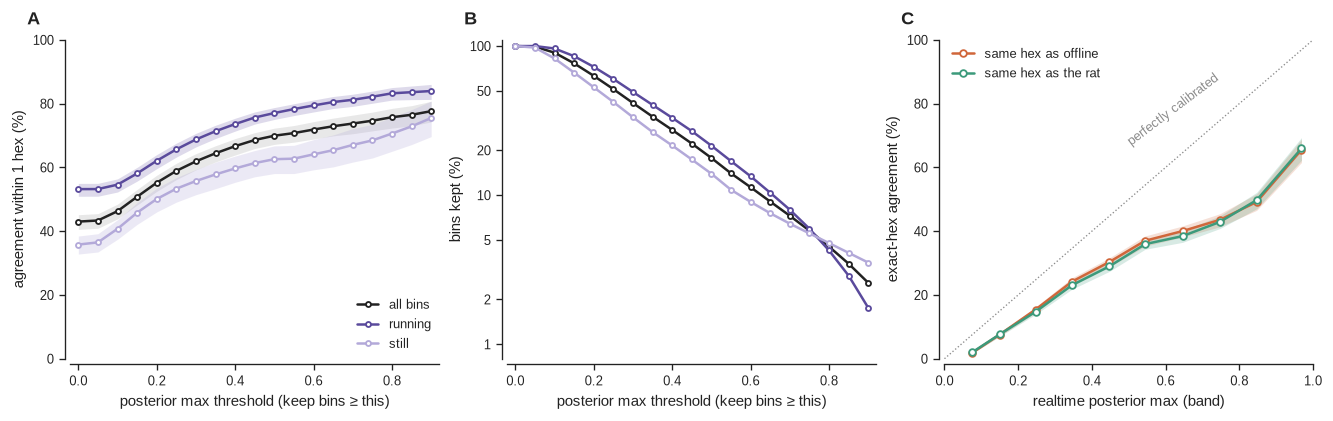

calibration (non-cumulative bands of post_max):


,post_max (mean),n,exact vs offline rate,exact vs offline lo,exact vs offline hi,exact vs rat rate,exact vs rat lo,exact vs rat hi,within 1 hex rate
post_max,,,,,,,,,
"(0.0, 0.1]",0.075,44600,1.8,1.6,2.1,2.0,1.7,2.3,12.7
"(0.1, 0.2]",0.150,124056,7.6,7.1,8.0,7.6,7.0,8.2,25.5
"(0.2, 0.3]",0.247,99004,15.4,14.5,16.2,14.7,13.9,15.5,42.3
"(0.3, 0.4]",0.346,64520,24.2,22.8,25.4,23.1,21.8,24.2,52.7
"(0.4, 0.5]",0.447,44074,30.3,28.8,31.6,29.0,27.4,30.2,60.6
"(0.5, 0.6]",0.544,29546,37.0,35.3,38.5,35.9,34.3,37.3,66.5
"(0.6, 0.7]",0.646,18426,40.0,38.2,41.6,38.5,36.5,40.2,68.5
"(0.7, 0.8]",0.747,12632,43.5,41.4,45.5,42.9,40.8,44.8,70.5
"(0.8, 0.9]",0.847,8841,49.2,46.5,51.7,49.7,47.0,52.2,73.2


closed-loop view, all bins (wait = time between consecutive bins that pass the threshold):


,% bins kept,kept bins / s,agree %,exact agree %,near rat %,% running,% still,median wait ms,90th pct wait ms
posterior max >=,,,,,,,,,
0.0,100.0,166.7,43.0,19.8,42.9,46.8,31.9,6.0,6.0
0.1,90.3,150.4,46.3,21.7,46.2,49.9,29.2,6.0,6.0
0.2,63.1,105.2,55.2,27.7,54.9,53.7,26.8,6.0,18.0
0.3,41.5,69.2,61.9,34.2,61.4,55.4,25.6,6.0,30.0
0.4,27.4,45.7,66.7,39.3,66.1,56.4,25.1,6.0,54.0
0.5,17.8,29.6,69.9,44.2,69.3,56.5,25.0,12.0,84.0
0.6,11.3,18.8,71.9,48.3,71.3,55.4,25.5,18.0,132.0
0.7,7.3,12.1,73.8,52.8,72.9,51.3,28.3,30.0,216.0
0.8,4.5,7.5,75.7,58.5,74.3,44.1,33.7,42.0,360.0


In [15]:
pm      = pairs.post_max.to_numpy()
THRESH  = np.round(np.arange(0, 0.91, 0.05), 2)
GROUPS  = [('all bins', np.ones(len(pairs), bool), INK, .1),
           ('running',  pairs.running.to_numpy(),  RUN_C, .2),
           ('still',    pairs.still.to_numpy(),    STILL_C, .25)]
one     = pd.Series(0, index=pairs.index)              # a single group, for boot_rate

curves = {}
for lab, m, _, _ in GROUPS:
    rows = []
    for t in THRESH:
        keep = m & (pm >= t)
        if keep.sum() < MIN_N:
            break
        r = boot_rate(pairs.agree[keep], one[keep], pairs[keep]).iloc[0]
        rows.append({'threshold': t, 'rate': r.rate, 'lo': r.lo, 'hi': r.hi, 'kept %': 100 * keep.sum() / m.sum()})
    curves[lab] = pd.DataFrame(rows).set_index('threshold')

# calibration: agreement inside narrow bands of post_max
band  = pd.cut(pairs.post_max, np.arange(0, 1.01, 0.1))
known = pairs.of_act > 0
cal = pd.DataFrame({
    'post_max (mean)': pairs.groupby(band, observed=True).post_max.mean(),
    'n'              : pairs.groupby(band, observed=True).size()})
cal = cal.join(boot_rate(pairs.agree_exact, band).add_prefix('exact vs offline ')[['exact vs offline rate', 'exact vs offline lo', 'exact vs offline hi']])
cal = cal.join(boot_rate((pairs.rt_err == 0)[known], band[known], pairs[known])
               .add_prefix('exact vs rat ')[['exact vs rat rate', 'exact vs rat lo', 'exact vs rat hi']])
cal = cal.join(boot_rate(pairs.agree, band).add_prefix(f'within {AGREE_TOL} hex ')[[f'within {AGREE_TOL} hex rate']])
cal = cal[cal.n >= MIN_N]

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(11, 3.4))
for lab, _, c, ba in GROUPS:
    cv = curves[lab]
    ci_line(a0, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
    a1.plot(cv.index, cv['kept %'], color=c, marker='o', ms=3, mfc='white', mew=1.1, label=lab)
a0.set_ylim(0, 100)
a0.set_ylabel(f'agreement within {AGREE_TOL} hex (%)')
a0.legend(loc='lower right')
a1.set_yscale('log')
a1.yaxis.set_major_formatter(PLAIN)
a1.set_yticks([1, 2, 5, 10, 20, 50, 100])
a1.minorticks_off()
a1.set_ylim(0.8, 110)
a1.set_ylabel('bins kept (%)')
for ax in (a0, a1):
    ax.set_xlim(-0.02, 0.92)
    ax.set_xlabel('posterior max threshold (keep bins ≥ this)')

x = cal['post_max (mean)']
a2.plot([0, 1], [0, 100], color=MUTED, lw=0.8, ls=':')
a2.annotate('perfectly calibrated', xy=(0.62, 66), rotation=37, fontsize=7.5, color=MUTED, ha='center', va='bottom')
ci_line(a2, x, cal.rename(columns={'exact vs offline rate': 'rate', 'exact vs offline lo': 'lo', 'exact vs offline hi': 'hi'}),
        OF, label='same hex as offline')
ci_line(a2, x, cal.rename(columns={'exact vs rat rate': 'rate', 'exact vs rat lo': 'lo', 'exact vs rat hi': 'hi'}),
        TRUE, label="same hex as the rat")
a2.set_xlim(0, 1)
a2.set_ylim(0, 100)
a2.set_xlabel('realtime posterior max (band)')
a2.set_ylabel('exact-hex agreement (%)')
a2.legend(loc='upper left')
letter([a0, a1, a2])
show(fig, 'fig11_confidence_threshold')

print('calibration (non-cumulative bands of post_max):')
display(cal.round(1).assign(**{'post_max (mean)': cal['post_max (mean)'].round(3)}))

rows = []
dur_s = len(pairs) * BIN_S
for t in [0, .1, .2, .3, .4, .5, .6, .7, .8, .9]:
    keep = pm >= t
    sel  = pairs[keep]
    wait = np.diff(np.flatnonzero(keep)) * BIN_S * 1e3          # ms between consecutive kept bins
    rows.append({'posterior max >=': t,
                 '% bins kept'     : 100 * keep.mean(),
                 'kept bins / s'   : keep.sum() / dur_s,
                 'agree %'         : 100 * sel.agree.mean(),
                 'exact agree %'   : 100 * sel.agree_exact.mean(),
                 'near rat %'      : 100 * sel.rt_err[sel.of_act > 0].between(0, AGREE_TOL).mean(),
                 '% running'       : 100 * sel.running.mean(),
                 '% still'         : 100 * sel.still.mean(),
                 'median wait ms'  : np.median(wait),
                 '90th pct wait ms': np.percentile(wait, 90)})
print('closed-loop view, all bins (wait = time between consecutive bins that pass the threshold):')
display(pd.DataFrame(rows).set_index('posterior max >=').round(1))

**Figure 11.** **A**, Agreement with offline (≤ 1 hex) among bins whose realtime posterior max is at or above
the threshold, for all, running and still bins. **B**, Share of each group's bins that pass the threshold (log axis).
**C**, Exact-hex agreement within 0.1-wide bands of posterior max (plotted at the band mean), against offline's decode
(orange) and the rat's true hex (green); dotted line: perfect calibration (agreement = posterior max). Bands: 95% CI.

**Takeaway.**

- **Agreement climbs steadily with the threshold:** 43% with no threshold, 62% at ≥ 0.3, 70% at ≥ 0.5 and 78% at
  ≥ 0.9. Running bins sit 15–20 points above still bins at every threshold.
- **The cost is steep.** ≥ 0.3 keeps 42% of bins (69 per second); ≥ 0.5 keeps 18% (30 per second); ≥ 0.8 keeps 4.5%
  (7.5 per second), and then 1 wait in 10 between usable bins is longer than 360 ms.
- **At the highest thresholds the survivors shift toward rest:** at ≥ 0.9, 44% of the kept bins are still bins,
  against 32% overall. The decoder is sometimes very sure of itself at rest, so a high threshold does not just select running.
- **The confidence is overconfident.** In every band, the decoder's chosen hex is right less often than its posterior
  claims. When it says about 45%, it matches the rat's hex 29% of the time; at about 97%, 66%. Agreement with offline
  tracks the rat almost exactly. So `post_max` works as a *ranking* of bins but should not be read as a probability.
  What makes it overconfident isn't tested here.
- **For a closed-loop trigger, ≥ 0.4–0.5 is a reasonable middle:** 67–70% agreement, 30–46 usable bins per second,
  a median wait of 6–12 ms, and 90% of waits under 54–84 ms.

### 12b · Non-local content under the threshold

Here **non-local** means a decode **2 or more hex steps from the rat's true hex** (more than 1 hex away); bins where
the rat's position is unknown are left out. Two ways to anchor it:

- **Realtime-defined** (requests 1–2): bins where the *realtime* decode is non-local. *Kept* = the bin still passes the
  threshold. Of the kept ones, how many agree with offline (within 1 hex)?
- **Offline-defined**: bins where the *offline* decode is non-local, which is closer to genuine non-local content if you
  trust the smoother. *Kept* = the realtime bin at that moment passes the threshold; agreement = realtime lands within
  1 hex of offline's non-local decode.

Keep the base rates (first table) in mind: realtime calls most bins non-local, offline calls few. `thr_curve()`,
defined here, is the threshold version of `boot_rate()` and is used by the rest of §12.

share of bins that are non-local (rat position known):


,all bins,running,still
realtime non-local %,57.1,46.2,65.6
offline non-local %,13.3,12.6,13.8
both non-local %,10.2,8.2,12.2


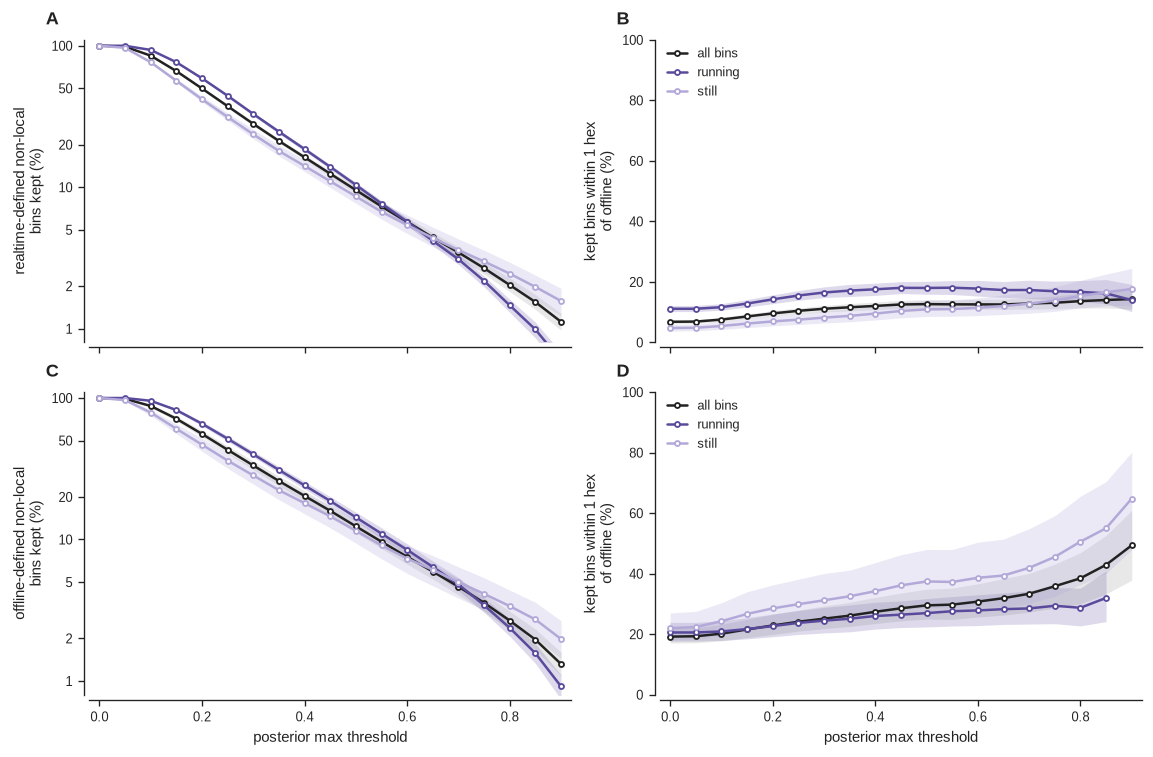

all bins:


non-local bins kept %  \
view             posterior max >=                          
realtime-defined 0.0                               100.0   
                 0.3                                28.0   
                 0.5                                 9.6   
                 0.7                                 3.5   
                 0.9                                 1.1   
offline-defined  0.0                               100.0   
                 0.3                                33.4   
                 0.5                                12.4   
                 0.7                                 4.6   
                 0.9                                 1.3   

                                   kept non-local bins / s  \
view             posterior max >=                            
realtime-defined 0.0                                  95.1   
                 0.3                                  26.7   
                 0.5                                   9.1   
                 0.7                                   3.3   
                 0.9                                   1.1   
offline-defined  0.0                                  22.1   
                 0.3                                   7.4   
                 0.5                                   2.7   
                 0.7                                   1.0   
                 0.9                                   0.3   

                                   agree with offline %  \
view             posterior max >=                         
realtime-defined 0.0                                6.8   
                 0.3                               11.1   
                 0.5                               12.7   
                 0.7                               12.9   
                 0.9                               14.3   
offline-defined  0.0                               19.2   
                 0.3                               25.1   
                 0.5                               29.5   
                 0.7                               33.4   
                 0.9                               49.4   

                                   offline also non-local %  \
view             posterior max >=                             
realtime-defined 0.0                                   17.9   
                 0.3                                   19.3   
                 0.5                                   20.5   
                 0.7                                   22.1   
                 0.9                                   22.0   
offline-defined  0.0                                  100.0   
                 0.3                                  100.0   
                 0.5                                  100.0   
                 0.7                                  100.0   
                 0.9                                  100.0   

                                   realtime also non-local %  
view             posterior max >=                             
realtime-defined 0.0                                   100.0  
                 0.3                                   100.0  
                 0.5                                   100.0  
                 0.7                                   100.0  
                 0.9                                   100.0  
offline-defined  0.0                                    77.2  
                 0.3                                    69.8  
                 0.5                                    68.0  
                 0.7                                    70.9  
                 0.9                                    80.7

In [16]:
def thr_curve(blocks, num, den, thresholds=THRESH, min_n=MIN_N):
    # rate (%) = count(num(t)) / count(den(t)) at each threshold t, with a 95% block-bootstrap CI.
    # num / den return boolean masks over the units (bins or events); blocks = each unit's 30 s block
    K = np.array([np.bincount(blocks[num(t)], minlength=NB) for t in thresholds], float)
    N = np.array([np.bincount(blocks[den(t)], minlength=NB) for t in thresholds], float)
    with np.errstate(invalid='ignore', divide='ignore'):
        bs = (BOOT_W @ K.T) / (BOOT_W @ N.T)
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    out = pd.DataFrame({'rate': 100 * K.sum(1) / N.sum(1), 'lo': 100 * lo, 'hi': 100 * hi, 'n': N.sum(1)},
                       index=pd.Index(thresholds, name='threshold'))
    return out[out.n >= min_n]

blk   = pairs.block.to_numpy()
known = (pairs.of_act > 0).to_numpy()
agree = pairs.agree.to_numpy()
rt_nl = known & (pairs.rt_err >= 2).to_numpy()
of_nl = known & (pairs.of_err >= 2).to_numpy()
VIEWS = {'realtime-defined': rt_nl, 'offline-defined': of_nl}

print('share of bins that are non-local (rat position known):')
display(pd.DataFrame({lab: {'realtime non-local %': 100 * rt_nl[m].sum() / known[m].sum(),
                            'offline non-local %' : 100 * of_nl[m].sum() / known[m].sum(),
                            'both non-local %'    : 100 * (rt_nl & of_nl)[m].sum() / known[m].sum()}
                      for lab, m, _, _ in GROUPS}).round(1))

NL = {}
for view, flag in VIEWS.items():
    for lab, m, _, _ in GROUPS:
        base = flag & m
        NL[view, lab, 'kept']  = thr_curve(blk, lambda t: base & (pm >= t), lambda t: base)
        NL[view, lab, 'agree'] = thr_curve(blk, lambda t: base & (pm >= t) & agree, lambda t: base & (pm >= t))

def nl_grid(curves, series, name, unit='bins'):
    # 2 x 2: rows = realtime- / offline-defined non-local, columns = % kept (log) / % agreeing among kept
    fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.2), sharex=True)
    for r_, view in enumerate(VIEWS):
        for c_, metric in enumerate(['kept', 'agree']):
            ax = axes[r_, c_]
            for lab, color, ba in series(view):
                cv = curves[view, lab, metric]
                ci_line(ax, cv.index, cv, color, label=lab, band_alpha=ba, ms=3)
            if metric == 'kept':
                ax.set_yscale('log'); ax.yaxis.set_major_formatter(PLAIN)
                ax.set_yticks([1, 2, 5, 10, 20, 50, 100]); ax.minorticks_off(); ax.set_ylim(0.8, 110)
                ax.set_ylabel(f'{view} non-local\n{unit} kept (%)')
            else:
                ax.set_ylim(0, 100)
                ax.set_ylabel(f'kept bins within {AGREE_TOL} hex\nof offline (%)' if unit == 'bins' else
                              f'kept events with a bin within\n{AGREE_TOL} hex of offline (%)')
            ax.set_xlim(-0.02, 0.92)
        axes[r_, 1].legend(loc='upper left', fontsize=7.5)
    for ax in axes[1]:
        ax.set_xlabel('posterior max threshold')
    letter(axes)
    show(fig, name)

nl_grid(NL, lambda view: [(lab, c, ba) for lab, _, c, ba in GROUPS], 'fig12_nonlocal_threshold')

rows = []
for view, flag in VIEWS.items():
    for t in [0, .3, .5, .7, .9]:
        kept = flag & (pm >= t)
        rows.append({'view': view, 'posterior max >=': t, 'non-local bins kept %': 100 * kept.sum() / flag.sum(),
                     'kept non-local bins / s': kept.sum() / (len(pairs) * BIN_S),
                     'agree with offline %': 100 * agree[kept].mean(),
                     'offline also non-local %': 100 * of_nl[kept].mean(),
                     'realtime also non-local %': 100 * rt_nl[kept].mean()})
print('all bins:')
display(pd.DataFrame(rows).set_index(['view', 'posterior max >=']).round(1))

**Figure 12.** Non-local bins (decode ≥ 2 hexes from the rat) under the posterior-max threshold.
**A, B**, Realtime-defined: share of realtime's non-local bins that pass the threshold (A, log axis), and of those, the
share within 1 hex of offline (B). **C, D**, Offline-defined: share of offline's non-local bins whose realtime bin
passes the threshold (C), and of those, the share where realtime lands within 1 hex of offline (D). Bands: 95% CI;
curves end where fewer than 300 bins remain.

**Takeaway.**

- **Request 1: how much realtime non-local content survives.** A little less than everything else: 28% of realtime's
  non-local bins pass 0.3, 9.6% pass 0.5 and 3.5% pass 0.7 (all bins: 42%, 18%, 7%). Running and still behave alike.
- **Request 2: do the survivors agree with offline?** Rarely, and the threshold barely helps: 7% with no threshold,
  13% at ≥ 0.5, 14% at ≥ 0.9. Running survivors do a bit better (11% → 18% at 0.5) than still ones (5% → 11%). In
  about 80% of realtime's confident non-local bins, offline isn't non-local at all. These are mostly realtime errors
  (the corner blind spot, A6), not replay.
- **Offline-defined view: here the threshold does help.** When offline decodes non-local content, the realtime bin
  passes the threshold at a similar rate (33% at 0.3, 12% at 0.5), but agreement among those climbs: 19% → 30% at
  0.5 → 49% at 0.9. At rest it climbs most: 22% → 37% at 0.5 → 65% at 0.9 (398 bins). So a high threshold enriches
  for correct non-local content, but keeps very little of it: at ≥ 0.5, about 2.7 of offline's non-local bins per
  second survive.

### 12c · Spike content under the threshold

Of the bins that pass the threshold, how many had no spikes of their own, or at most one? The table underneath shows
why the answer drops so fast: how confident the decoder tends to be in bins with 0, 1, 2 or 3+ spikes.

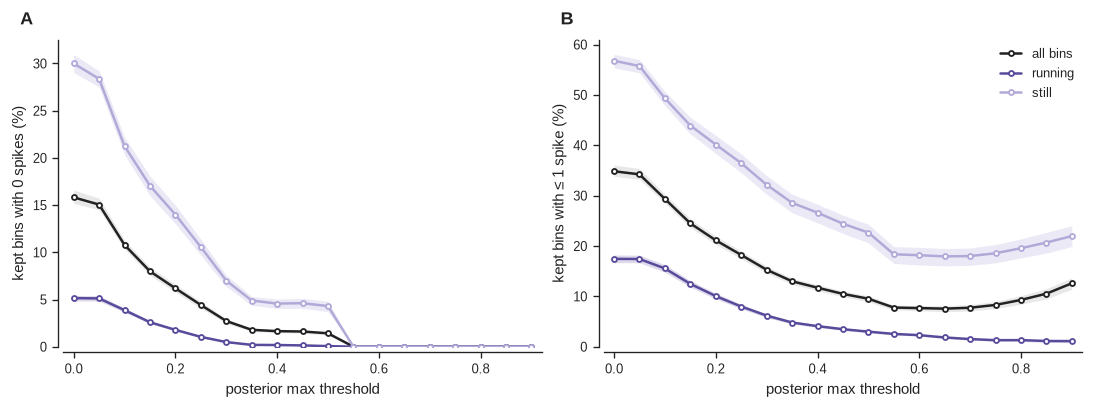

realtime posterior max, by spikes in the bin:


,count,50%,90%,99%,max,% passing >= 0.3,% passing >= 0.5,% passing >= 0.7
spikes,,,,,,,,
0,72390.0,0.122,0.275,0.511,0.516,7.139,1.594,0.000
1,86996.0,0.199,0.455,0.996,1.000,27.402,7.576,2.962
2,84177.0,0.247,0.564,0.999,1.000,38.564,13.917,5.328
3+,213970.0,0.354,0.743,0.996,1.000,60.010,28.891,12.266


In [17]:
zero_spk = (pairs.spikes == 0).to_numpy()
le1_spk  = (pairs.spikes <= 1).to_numpy()
SPK = {}
for lab, m, _, _ in GROUPS:
    for nm, s in [('0', zero_spk), ('<=1', le1_spk)]:
        SPK[lab, nm] = thr_curve(blk, lambda t: m & (pm >= t) & s, lambda t: m & (pm >= t))

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 3.3), sharex=True)
for ax, nm, yl in [(a0, '0', 'kept bins with 0 spikes (%)'), (a1, '<=1', 'kept bins with ≤ 1 spike (%)')]:
    for lab, _, c, ba in GROUPS:
        ci_line(ax, SPK[lab, nm].index, SPK[lab, nm], c, label=lab, band_alpha=ba, ms=3)
    ax.set_ylim(0, None)
    ax.set_xlim(-0.02, 0.92)
    ax.set_xlabel('posterior max threshold')
    ax.set_ylabel(yl)
a1.legend(loc='upper right')
letter([a0, a1])
show(fig, 'fig13_spikes_threshold')

spk_lab = pairs.spikes.clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
q = pairs.groupby(spk_lab).post_max.describe(percentiles=[.5, .9, .99])[['count', '50%', '90%', '99%', 'max']]
for t in [.3, .5, .7]:
    q[f'% passing >= {t}'] = 100 * pairs.groupby(spk_lab).post_max.agg(lambda s: (s >= t).mean())
print('realtime posterior max, by spikes in the bin:')
display(q.round(3))

**Figure 13.** Share of the bins passing each threshold that had **A**, no spikes, or **B**, at most one spike
in the 6 ms bin. Bands: 95% CI.

**Takeaway.**

- **Zero-spike bins disappear quickly, then entirely.** They are 16% of all bins, 2.7% of bins at ≥ 0.3, 1.4% at
  ≥ 0.5, and none above 0.52; the most confident a zero-spike bin ever gets is 0.516. At rest the share drops from 30%
  to about 5% at 0.35–0.5, then to zero.
- **Single-spike bins don't.** The share with ≤ 1 spike falls from 35% to about 8% at 0.55–0.65, then *rises* again,
  to 13% at ≥ 0.9 and to 22% at rest. One spike can push the posterior above 0.99 (99th percentile of 1-spike bins:
  0.996). So the most confident bins are not necessarily the best-evidenced ones, which fits the overconfidence in
  12a, panel C.

### 12d · Non-local content by distance from the rat

The same two views as 12b, split by **how far** from the rat the non-local decode is: 2 hexes (just past the
neighbours), 3–4, or 5+ (across the maze). Darker = farther. Blue shades split the realtime-defined bins by the
realtime decode's distance; orange shades split the offline-defined bins by offline's distance.

how the non-local bins split by distance (% of each view's non-local bins):


,realtime-defined,offline-defined
2 hexes,17.3,18.8
3–4 hexes,19.6,21.8
5+ hexes,63.2,59.4


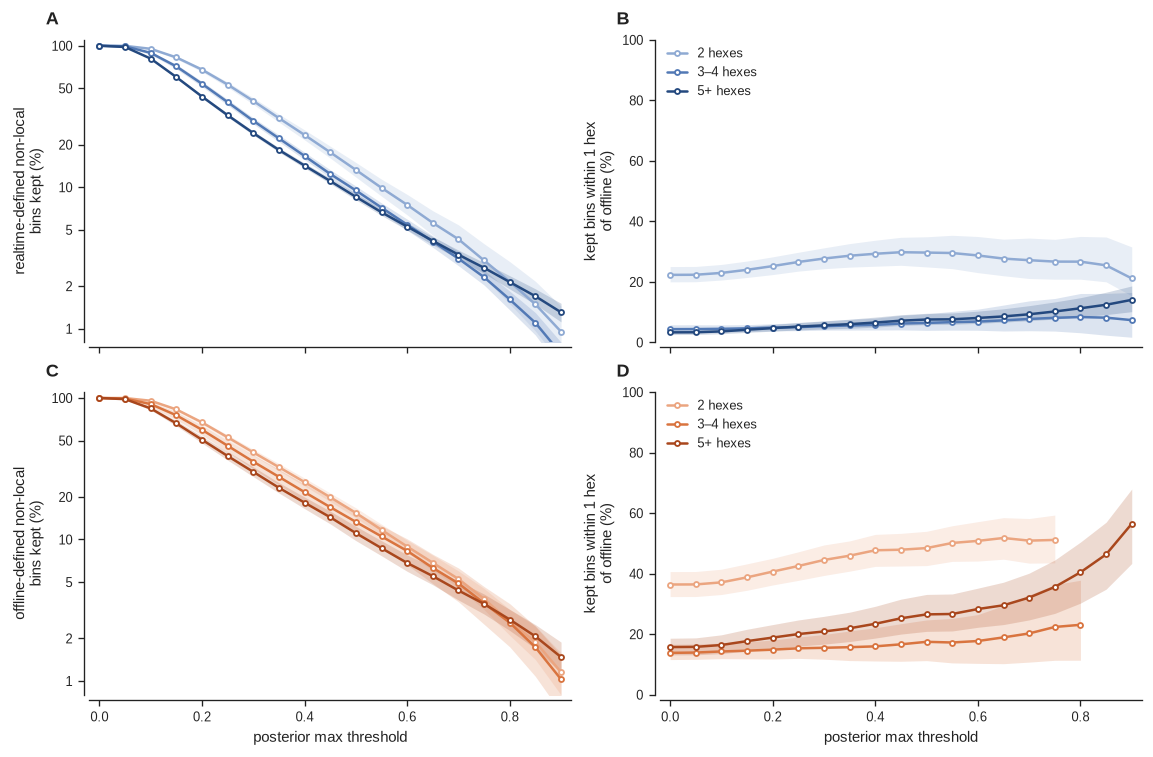

In [18]:
DIST = [('2 hexes', 2, 2), ('3–4 hexes', 3, 4), ('5+ hexes', 5, 99)]
RAMP = {'realtime-defined': ['#8faad3', '#5279b5', '#24497f'], 'offline-defined': ['#eba580', '#d9743f', '#a9471d']}
ERR  = {'realtime-defined': pairs.rt_err.to_numpy(), 'offline-defined': pairs.of_err.to_numpy()}

DS = {}
for view in VIEWS:
    for lab, lo_, hi_ in DIST:
        base = known & (ERR[view] >= lo_) & (ERR[view] <= hi_)
        DS[view, lab, 'kept']  = thr_curve(blk, lambda t: base & (pm >= t), lambda t: base)
        DS[view, lab, 'agree'] = thr_curve(blk, lambda t: base & (pm >= t) & agree, lambda t: base & (pm >= t))

print('how the non-local bins split by distance (% of each view\'s non-local bins):')
display(pd.DataFrame({view: {lab: 100 * (known & (ERR[view] >= lo_) & (ERR[view] <= hi_)).sum() / VIEWS[view].sum()
                             for lab, lo_, hi_ in DIST} for view in VIEWS}).round(1))

nl_grid(DS, lambda view: [(lab, col, .2) for (lab, _, _), col in zip(DIST, RAMP[view])],
        'fig14_nonlocal_distance')

**Figure 14.** As Figure 12, split by the non-local decode's distance from the rat: 2 hexes (light), 3–4,
and 5+ (dark). **A, B**, Realtime-defined (blue shades: realtime's distance). **C, D**, Offline-defined (orange shades:
offline's distance). Bands: 95% CI; curves end where fewer than 300 bins remain.

**Takeaway.**

- **Most non-local decodes are far jumps:** 63% of realtime's and 59% of offline's non-local bins are 5+ hexes from the rat.
- **Realtime's far jumps almost never match offline.** Its 3–4 and 5+ hex decodes agree with offline 3–4% of the time
  with no threshold, and only 7–14% even at ≥ 0.9. Its 2-hex decodes agree 22–30% of the time, mostly near-misses
  next to where offline is.
- **For offline's far content, a high threshold matters a lot.** When offline decodes 5+ hexes away, realtime agrees
  16% of the time with no threshold, 27% at ≥ 0.5 and 57% at ≥ 0.9 (531 bins). Offline's 2-hex content goes from 36% to
  49% at ≥ 0.5; the 3–4 hex group stays low (14–22%).

### 12e · Event-level preservation

A closed-loop trigger acts on *events*, not single bins: one confident bin during a replay is enough to fire. An
**event** here is a run of at least `MIN_EVENT_BINS` = 3 consecutive non-local bins (≥ 18 ms), defined separately for
each view; that keeps 91% of realtime's and 99% of offline's non-local time. At each threshold:

- an event is **kept** if *at least one* of its bins passes the threshold;
- a kept event **agrees** if at least one of its passing bins is also within 1 hex of offline.

Events are grouped by the rat's mean speed during the event (running > 10 cm/s, still < 2 cm/s). CIs resample
events by the 30 s block they start in.

events (≥ 3 consecutive non-local bins):


,realtime-defined,offline-defined
events,13342.0,1833.0
per minute,291.6,40.1
median ms,42.0,72.0
% running,52.6,65.5
% still,25.8,18.0


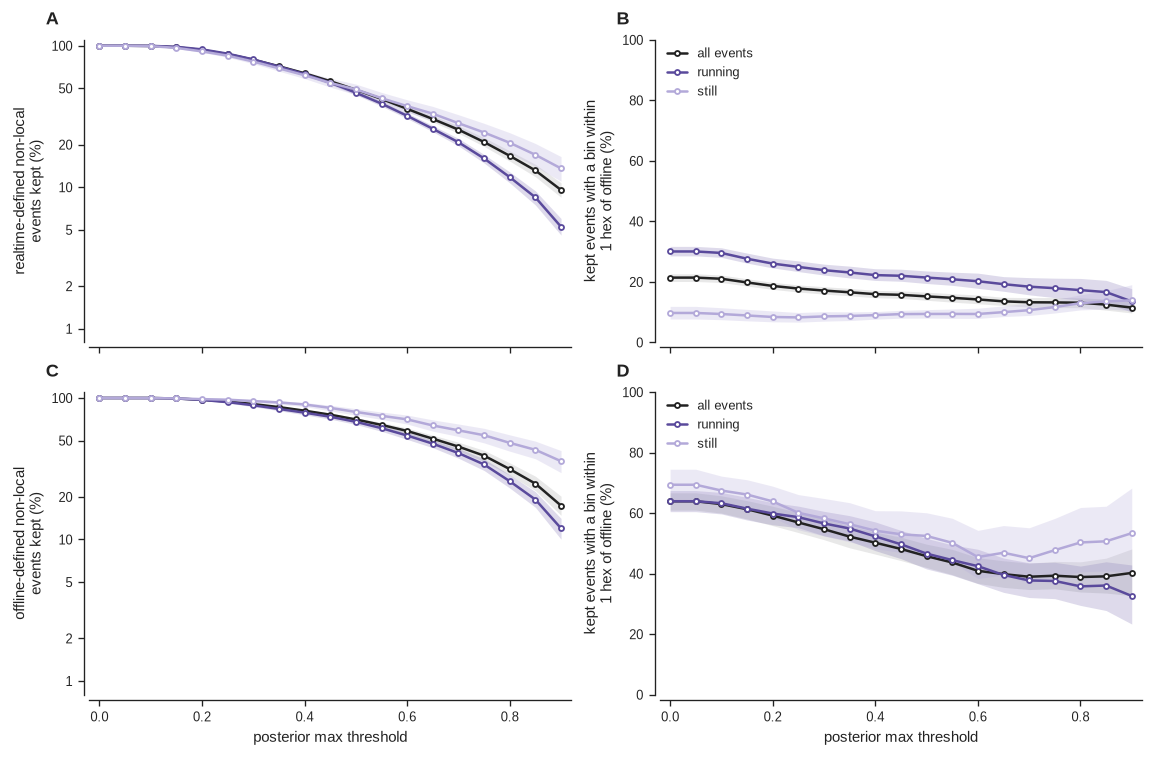

all events:


events kept %  kept events agreeing %  \
view             posterior max >=                                          
realtime-defined 0.0                       100.0                    21.4   
                 0.3                        79.7                    17.1   
                 0.5                        48.8                    15.2   
                 0.7                        25.5                    13.3   
                 0.9                         9.6                    11.5   
offline-defined  0.0                       100.0                    63.9   
                 0.3                        90.6                    54.7   
                 0.5                        70.5                    45.8   
                 0.7                        45.3                    39.0   
                 0.9                        17.3                    40.3   

                                   events kept AND agreeing %  
view             posterior max >=                              
realtime-defined 0.0                                     21.4  
                 0.3                                     13.7  
                 0.5                                      7.4  
                 0.7                                      3.4  
                 0.9                                      1.1  
offline-defined  0.0                                     63.9  
                 0.3                                     49.5  
                 0.5                                     32.3  
                 0.7                                     17.7  
                 0.9                                      7.0

In [19]:
MIN_EVENT_BINS = 3

def seg_max(v, st, sp):
    # max of v over each [st, sp) segment
    v = np.r_[v, -np.inf]
    return np.maximum.reduceat(v, np.ravel(np.c_[st, sp]))[::2]

def event_table(flag):
    x = np.r_[0, flag.astype(int), 0]
    e = np.flatnonzero(np.diff(x))
    st, sp = e[::2], e[1::2]
    st, sp = st[sp - st >= MIN_EVENT_BINS], sp[sp - st >= MIN_EVENT_BINS]
    spd = np.r_[0, np.cumsum(pairs.speed.to_numpy())]
    ev = pd.DataFrame({'start': st, 'stop': sp, 'dur_ms': (sp - st) * BIN_S * 1e3, 'block': blk[st],
                       'speed': (spd[sp] - spd[st]) / (sp - st),
                       'pm_max': seg_max(pm, st, sp),                               # best bin in the event
                       'pm_agree_max': seg_max(np.where(agree, pm, -1.0), st, sp)})  # best agreeing bin
    return ev

EV = {view: event_table(flag) for view, flag in VIEWS.items()}
print('events (≥ 3 consecutive non-local bins):')
display(pd.DataFrame({view: {'events': len(ev), 'per minute': len(ev) / (len(pairs) * BIN_S / 60),
                             'median ms': ev.dur_ms.median(), '% running': 100 * (ev.speed > RUN_SPEED).mean(),
                             '% still': 100 * (ev.speed < STILL_SPEED).mean()} for view, ev in EV.items()}).round(1))

EC = {}
for view, ev in EV.items():
    b = ev.block.to_numpy()
    for lab, m in [('all events', np.ones(len(ev), bool)), ('running', (ev.speed > RUN_SPEED).to_numpy()),
                   ('still', (ev.speed < STILL_SPEED).to_numpy())]:
        EC[view, lab, 'kept']  = thr_curve(b, lambda t: m & (ev.pm_max.to_numpy() >= t), lambda t: m, min_n=30)
        EC[view, lab, 'agree'] = thr_curve(b, lambda t: m & (ev.pm_agree_max.to_numpy() >= t),
                                           lambda t: m & (ev.pm_max.to_numpy() >= t), min_n=30)

nl_grid(EC, lambda view: [('all events', INK, .1), ('running', RUN_C, .2), ('still', STILL_C, .25)],
        'fig15_nonlocal_events', unit='events')
rows = []
for view, ev in EV.items():
    for t in [0, .3, .5, .7, .9]:
        k_ = ev.pm_max >= t
        rows.append({'view': view, 'posterior max >=': t, 'events kept %': 100 * k_.mean(),
                     'kept events agreeing %': 100 * (ev.pm_agree_max[k_] >= t).mean(),
                     'events kept AND agreeing %': 100 * (ev.pm_agree_max >= t).mean()})
print('all events:')
display(pd.DataFrame(rows).set_index(['view', 'posterior max >=']).round(1))

**Figure 15.** Event-level version of Figure 12. An event is ≥ 3 consecutive non-local bins (≥ 18 ms).
**A, C**, Share of events with at least one bin passing the threshold. **B, D**, Of those, the share with at least one
passing bin within 1 hex of offline. Events are grouped by the rat's mean speed during the event. Bands: 95% CI
(events resampled by 30 s block); curves end where fewer than 30 events remain.

**Takeaway.**

- **Events are much more forgiving than bins.** At ≥ 0.5, 71% of offline's non-local events still have at least one
  passing bin (bins: 12%); at ≥ 0.7, 45% (bins: 4.6%). Still events survive best: at ≥ 0.9, 35% of them, against 12%
  of running ones.
- **But the matching content thins out.** Of the kept offline events, the share with a passing bin that agrees with
  offline falls from 64% with no threshold to 46% at ≥ 0.5 and about 40% at ≥ 0.7–0.9. Kept *and* agreeing: 64% → 32%
  at 0.5 → 18% at 0.7.
- **Realtime's own non-local events are mostly noise.** It produces 292 a minute (offline: 40), median 42 ms. At ≥ 0.5
  about 140 a minute still pass, and only 15% of those match offline.
- **Two-thirds of offline's non-local events happen while the rat runs** (> 10 cm/s), and only 18% at rest. Much of
  offline's non-local content is during movement (look-ahead sequences, or position-tracking lag), not rest replay.
  Keep that in mind before reading "non-local" as "replay".

### 12f · Detector view — treating offline's non-local bins as the reference

Requests 1–2 rolled into one trade-off. Think of the realtime decoder as a **non-local detector**: it "detects" when its
decode is non-local *and* its posterior max passes the threshold. Scored against offline's non-local bins:

- **precision** — of the realtime detections, how many are real (offline is non-local too);
- **recall** — of offline's non-local bins, how many the realtime decoder detects.

Two strictness levels: **same place** (realtime also lands within 1 hex of offline's decode) and **any non-local**
(offline is non-local anywhere, regardless of where realtime points). Each curve runs from threshold 0 (right end,
everything detected) to 0.9 (left end); the dotted line in B is the chance precision, i.e. how often offline is
non-local at all.

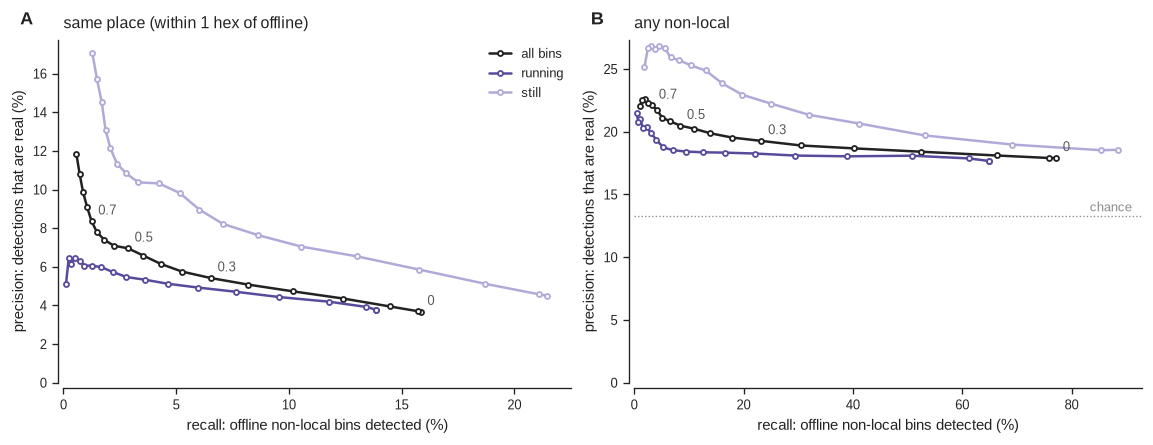

all bins (labels on the curves are thresholds):


,detections,detections / s,precision same %,recall same %,precision any %,recall any %
threshold,,,,,,
0.0,260973,95.1,3.7,15.8,17.9,77.2
0.3,73173,26.7,5.4,6.5,19.3,23.3
0.5,24923,9.1,7.0,2.9,20.5,8.4
0.7,9031,3.3,8.4,1.2,22.1,3.3
0.9,2922,1.1,11.8,0.6,22.0,1.1


In [20]:
rows = []
for lab, m, _, _ in GROUPS:
    ref = of_nl & m
    for t in THRESH:
        det = rt_nl & m & (pm >= t)
        if det.sum() < MIN_N:
            break
        same, anyh = det & of_nl & agree, det & of_nl
        rows.append({'group': lab, 'threshold': t, 'detections': int(det.sum()),
                     'detections / s': det.sum() / (len(pairs) * BIN_S),
                     'precision same %': 100 * same.sum() / det.sum(), 'recall same %': 100 * same.sum() / ref.sum(),
                     'precision any %' : 100 * anyh.sum() / det.sum(), 'recall any %' : 100 * anyh.sum() / ref.sum()})
DET = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for ax, kind, ttl in [(axes[0], 'same', 'same place (within 1 hex of offline)'), (axes[1], 'any', 'any non-local')]:
    for lab, _, c, _ in GROUPS:
        d = DET[DET.group == lab]
        ax.plot(d[f'recall {kind} %'], d[f'precision {kind} %'], color=c, marker='o', ms=3, mfc='white', mew=1.1, label=lab)
    d = DET[DET.group == 'all bins'].set_index('threshold')
    for t in [0.0, 0.3, 0.5, 0.7]:
        if t in d.index:
            ax.annotate(f'{t:g}', (d.loc[t, f'recall {kind} %'], d.loc[t, f'precision {kind} %']),
                        xytext=(4, 4), textcoords='offset points', fontsize=7.5, color=INK2)
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.set_xlabel('recall: offline non-local bins detected (%)')
    ax.set_ylabel('precision: detections that are real (%)')
    ax.set_title(ttl)
base_rate = 100 * of_nl.sum() / known.sum()
axes[1].axhline(base_rate, color=MUTED, lw=0.8, ls=':')
axes[1].annotate('chance', xy=(0.98, base_rate), xycoords=('axes fraction', 'data'), xytext=(0, 3),
                 textcoords='offset points', ha='right', fontsize=7.5, color=MUTED)
axes[0].legend(loc='upper right')
letter(axes)
show(fig, 'fig16_nonlocal_detector')
print('all bins (labels on the curves are thresholds):')
display(DET[(DET.group == 'all bins') & DET.threshold.isin([0, .3, .5, .7, .9])].drop(columns='group')
        .set_index('threshold').round(1))

**Figure 16.** Realtime non-local decodes treated as a detector of offline's non-local bins, swept over the
posterior-max threshold (numbers on the all-bins curve). **A**, A detection counts only if realtime lands within 1 hex
of offline's decode. **B**, A detection counts if offline is non-local anywhere; dotted line: chance precision
(offline's non-local rate).

**Takeaway.** As a non-local detector the realtime decoder is weak, and the threshold mostly trades recall
for small gains in precision.

- **Any non-local (B):** with no threshold it flags 77% of offline's non-local bins, but only 18% of its flags are
  real, against 13% by chance. At ≥ 0.7, precision reaches 22% while recall falls to 3%. At rest precision tops out
  around 27%.
- **Same place (A):** precision goes from 3.7% to 8.4% at ≥ 0.7 and 11.8% at ≥ 0.9, while recall falls from 16% to
  under 1%. At rest precision reaches about 17%.
- **In this run, the threshold isn't the lever for non-local content;** the corner blind spot (A6) and the loose prior
  (§14) are. Re-scoring this detector on the replayed decodes from §14 would show whether a slower prior fixes it.

## 13 · Disagreement over time — barrier shifts and other slow changes

Several things change *during* the epoch, and any of them could move the disagreement rate:

- **Barriers.** The maze has barriers that move between blocks. The stateScript log records 4 "Barrier shifted" events,
  so the epoch has 5 barrier blocks (B1–B5), and each shift moves exactly one barrier. **The realtime decoder ran
  with `blocked_hexes: []`**, so it never knew which hexes were closed and can decode into them. The offline file does
  know: its `decode_hex_open_status` column says, for every decoded hex, whether it is open right now.
- **The encoding model.** This is a *no-preload* run: the encoder starts empty and keeps learning from every running
  spike, so early minutes are decoded with much less training data.
- **Behaviour and spike supply** drift over the epoch too (more or less rest, more or fewer spikes).

**Where the barrier information comes from (and how sure it is):**

- *Shift times*: the stateScript log, whose clock is Trodes time in ms. Checked below: with that clock, the rat sits at
  a corner port hex in 99.5% of port pokes; shifting the clock by 2 s breaks it.
- *Closed hexes per block*: every hex that offline decodes with a status other than `open` during that block (6 per
  block, never contradicted within a block, and the rat never enters them), plus hexes 5, 17, 30 and 32. Those four
  are **inferred** as permanently closed: offline never decodes them and the rat never enters them all epoch.

Bins are grouped into *barrier blocks* (`barrier_block`, 1–5); the time course uses 30 s windows. Don't confuse either
with the 30 s *chunks* the bootstrap resamples.

In [21]:
FS  = cfg['sampling_rate']['spikes']
SSC = glob.glob(os.path.join(os.path.dirname(cfg['trodes']['config_file']), '*.stateScriptLog'))[0]
ssc = pd.DataFrame([l.split(' ', 1) for l in open(SSC, errors='ignore').read().splitlines()
                    if l[:1].isdigit() and ' ' in l], columns=['ms', 'msg'])
ssc['ms'] = ssc.ms.astype(np.int64)
ssc['minute'] = (ssc.ms * FS / 1000 - rt.trodes_sample.iloc[0]) / FS / 60     # minutes from the first realtime bin

# clock check: at each port poke ("UP n") the rat should be at a corner hex
pokes = ssc[ssc.msg.str.fullmatch(r'UP \d+')]
k = np.searchsorted(rt.trodes_sample.to_numpy(), pokes.ms.to_numpy() * FS // 1000).clip(0, len(rt) - 1)
print(f'clock check: rat at a corner hex (1-3) at {100*np.isin(rt.actual_hex.to_numpy()[k], [1, 2, 3]).mean():.1f}% '
      f'of {len(pokes)} port pokes')

SHIFT_MIN = ssc.minute[ssc.msg.str.contains('Barrier shifted')].to_numpy()
END_MIN   = ssc.minute[ssc.msg.str.contains('block is over')].to_numpy()
N_BB      = len(SHIFT_MIN) + 1

# closed hexes per barrier block, from offline's open-status column (+ hexes never open all epoch)
of_min   = (of.index.to_numpy(float) - rt.index[0]) / 60
of_bb    = np.searchsorted(SHIFT_MIN, of_min, side='right')
not_open = ~np.isin(of.decode_hex_open_status.astype(str).to_numpy(), ['open', 'None'])
seen     = set(of.decode_hex_any.unique()) | set(of.hex[of.hex > 0].unique())
ALWAYS_CLOSED = sorted(set(HEX_IDS) - seen)
CLOSED = [sorted(set(of.decode_hex_any.to_numpy()[(of_bb == b) & not_open].tolist()) | set(ALWAYS_CLOSED))
          for b in range(N_BB)]
CLOSED_MASK = np.zeros((N_BB, NH), bool)
for b, hs in enumerate(CLOSED):
    CLOSED_MASK[b, hs] = True

edges_min = np.r_[0, SHIFT_MIN, pairs.minute.max()]
bb_tab = pd.DataFrame({
    'start (min)': edges_min[:-1], 'end (min)': edges_min[1:],
    'closed hexes': [', '.join(map(str, c)) for c in CLOSED],
    'barrier moved at start': ['—'] + [f'{", ".join(map(str, sorted(set(CLOSED[b-1]) - set(CLOSED[b]))))} opened, '
                                       f'{", ".join(map(str, sorted(set(CLOSED[b]) - set(CLOSED[b-1]))))} closed'
                                       for b in range(1, N_BB)],
    'rat bins in closed hexes': [int(np.isin(of.hex.to_numpy()[of_bb == b], CLOSED[b]).sum()) for b in range(N_BB)],
}, index=pd.Index([f'B{b+1}' for b in range(N_BB)], name='barrier block'))
print(f'always closed (inferred): {ALWAYS_CLOSED}   ·   "block is over" messages at {np.round(END_MIN, 1)} min')
display(bb_tab.round(1))

pairs['barrier_block'] = np.searchsorted(SHIFT_MIN, pairs.minute, side='right') + 1
pairs['rt_closed'] = CLOSED_MASK[pairs.barrier_block - 1, pairs.rt_dec]
pairs['of_closed'] = CLOSED_MASK[pairs.barrier_block - 1, pairs.of_dec]

# encoding-model growth: every spike the encoder trained on (ENCODER_OUTPUT records, encode_spike = True)
enc = pd.read_hdf(sorted(glob.glob(f'{RUN_DIR}/*.rec_merged.h5'))[-1], 'rec_3')
enc_min = np.sort((enc.timestamp[enc.encode_spike].to_numpy() - rt.trodes_sample.iloc[0]) / FS / 60)
del enc
print(f'encoder trained on {len(enc_min):,} spikes over the epoch')

clock check: rat at a corner hex (1-3) at 99.5% of 389 port pokes
always closed (inferred): [5, 17, 30, 32]   ·   "block is over" messages at [13.1 34.1] min


,start (min),end (min),closed hexes,barrier moved at start,rat bins in closed hexes
barrier block,,,,,
B1,0.0,15.0,"5, 14, 16, 17, 23, 30, 32, 37, 39, 45",—,0
B2,15.0,25.4,"5, 16, 17, 19, 23, 30, 32, 37, 39, 45","14 opened, 19 closed",0
B3,25.4,35.5,"5, 16, 17, 19, 23, 30, 31, 32, 37, 39","45 opened, 31 closed",0
B4,35.5,41.1,"5, 17, 18, 19, 23, 30, 31, 32, 37, 39","16 opened, 18 closed",0
B5,41.1,46.0,"5, 17, 18, 19, 23, 24, 30, 32, 37, 39","31 opened, 24 closed",0


encoder trained on 880,522 spikes over the epoch


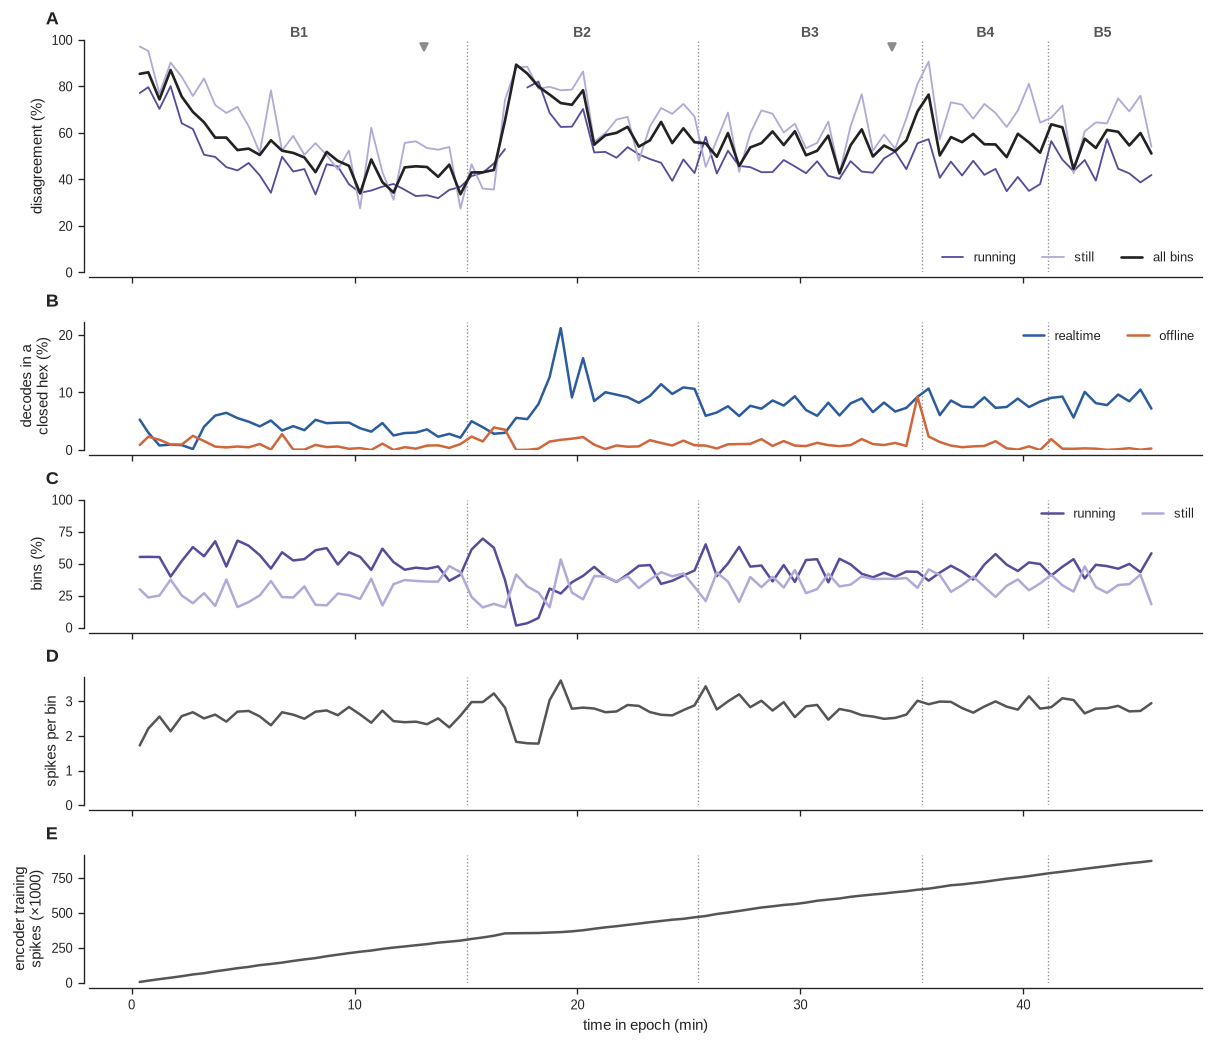

per barrier block (disagreement with 95% CI; still/running = share of the block's bins):


,minutes,disagree %,CI,disagree running %,disagree still %,% still,spikes / bin,realtime in closed hex %,offline in closed hex %,training spikes at start (k)
barrier block,,,,,,,,,,
B1,15.0,53.7,48.9–59.2,46.4,59.9,28.4,2.5,3.6,0.8,0.0
B2,10.4,63.7,58.4–69.5,51.3,68.3,32.5,2.7,9.1,1.4,306.4
B3,10.1,54.8,52.4–57.6,46.5,61.2,34.6,2.8,7.5,1.4,469.2
B4,5.7,57.4,53.7–61.8,42.8,71.0,34.7,2.9,8.2,0.8,668.9
B5,4.9,56.6,53.1–59.8,45.9,65.0,32.9,2.9,8.5,0.4,781.3


In [22]:
# per 30 s window
W  = pairs.groupby('block')
tc = pd.DataFrame({'minute'   : W.minute.mean(),
                   'disagree' : 100 * (1 - W.agree.mean()),
                   'rt_closed': 100 * W.rt_closed.mean(),
                   'of_closed': 100 * W.of_closed.mean(),
                   'still'    : 100 * W.still.mean(),
                   'running'  : 100 * W.running.mean(),
                   'spikes'   : W.spikes.mean()})
for state in ['running', 'still']:
    g = pairs[pairs[state]].groupby('block').agree
    tc[f'disagree {state}'] = (100 * (1 - g.mean())).where(g.size() >= 100)   # NaN if < 100 bins in that state
enc_k = np.searchsorted(enc_min, tc.minute) / 1e3                               # thousands of training spikes so far

fig, axes = plt.subplots(5, 1, figsize=(10, 8.6), sharex=True, height_ratios=[2, 1.1, 1.1, 1.1, 1.1])
a0, a1, a2, a3, a4 = axes
a0.plot(tc.minute, tc['disagree running'], color=RUN_C, lw=1.1, label='running')
a0.plot(tc.minute, tc['disagree still'], color=STILL_C, lw=1.1, label='still')
a0.plot(tc.minute, tc.disagree, color=INK, lw=1.6, label='all bins')
a0.set_ylim(0, 100); a0.set_ylabel('disagreement (%)')
a0.legend(loc='lower right', ncol=3)
a1.plot(tc.minute, tc.rt_closed, color=RT, label='realtime')
a1.plot(tc.minute, tc.of_closed, color=OF, label='offline')
a1.set_ylim(0, None); a1.set_ylabel('decodes in a\nclosed hex (%)')
a1.legend(loc='upper right', ncol=2)
a2.plot(tc.minute, tc.running, color=RUN_C, label='running')
a2.plot(tc.minute, tc.still, color=STILL_C, label='still')
a2.set_ylim(0, 100); a2.set_ylabel('bins (%)')
a2.legend(loc='upper right', ncol=2)
a3.plot(tc.minute, tc.spikes, color=INK2)
a3.set_ylim(0, None); a3.set_ylabel('spikes per bin')
a4.plot(tc.minute, enc_k, color=INK2)
a4.set_ylim(0, None); a4.set_ylabel('encoder training\nspikes (×1000)')
a4.set_xlabel('time in epoch (min)')
for ax in axes:
    for m_ in SHIFT_MIN:
        ax.axvline(m_, color=MUTED, lw=0.8, ls=':', zorder=0)
mids = (edges_min[:-1] + edges_min[1:]) / 2
for b, m_ in enumerate(mids):
    a0.annotate(f'B{b+1}', xy=(m_, 1.0), xycoords=('data', 'axes fraction'), ha='center', va='bottom',
                fontsize=8.5, fontweight='bold', color=INK2)
a0.plot(END_MIN, np.full(len(END_MIN), 97), ls='none', marker='v', ms=5, color=MUTED)
letter(axes)
show(fig, 'fig17_time_course')

print('per barrier block (disagreement with 95% CI; still/running = share of the block\'s bins):')
by_bb = boot_rate(~pairs.agree, pairs.barrier_block)
summ = pd.DataFrame({
    'minutes'            : np.diff(edges_min),
    'disagree %'         : by_bb.rate.to_numpy(),
    'CI'                 : [f'{lo:.1f}–{hi:.1f}' for lo, hi in zip(by_bb.lo, by_bb.hi)],
    'disagree running %' : 100 * (1 - pairs[pairs.running].groupby('barrier_block').agree.mean()).to_numpy(),
    'disagree still %'   : 100 * (1 - pairs[pairs.still].groupby('barrier_block').agree.mean()).to_numpy(),
    '% still'            : 100 * pairs.groupby('barrier_block').still.mean().to_numpy(),
    'spikes / bin'       : pairs.groupby('barrier_block').spikes.mean().to_numpy(),
    'realtime in closed hex %': 100 * pairs.groupby('barrier_block').rt_closed.mean().to_numpy(),
    'offline in closed hex %' : 100 * pairs.groupby('barrier_block').of_closed.mean().to_numpy(),
    'training spikes at start (k)': np.searchsorted(enc_min, edges_min[:-1]) / 1e3,
}, index=bb_tab.index)
display(summ.round(1))

**Figure 17.** The epoch in 30 s windows. **A**, Disagreement for all, running and still bins (windows with
fewer than 100 bins in a state are left out). **B**, Share of decodes landing in a hex that is closed during that
barrier block, realtime vs offline. **C**, Share of running and still bins. **D**, Spikes per 6 ms bin. **E**, Cumulative
number of spikes the encoder has trained on. Dotted lines: barrier shifts (B1–B5 = barrier blocks); triangles: the
stateScript's "This block is over!" messages.

**Takeaway.**

- **Disagreement is not flat, but the barrier shifts are not where it jumps.** By barrier block it is 54%, 64%, 55%,
  57% and 57% (B1–B5). Only B2 stands out (95% CI 58–70%, against 49–59% for B1).
- **B2's excess comes from one ~3-minute stretch, 16.5–19.5 min**, where disagreement reaches ~90%. The rat stopped
  poking (no port pokes from 16.7 to 19.5 min) and stood almost motionless at **hex 11, mid-maze, right next to hex 14,
  which the first shift had just opened.** Offline decodes hex 11 throughout; realtime decodes hex 22, then the
  never-open hex 17. So the barrier change mattered mainly through behaviour: an unusual pause at a spot where the
  encoder had no training data for a resting rat (it only trains while running, A6).
- **The first minutes are bad for a different reason.** Disagreement starts near 85% and is down to about 50–55% by
  minutes 5–8 as the encoder fills up (panel E). This is a no-preload run, so the early minutes are decoded from very
  little training data.
- **Realtime decodes a closed hex in 6.8% of bins** (offline: about 1%): 3.6% in B1, 7.5–9% afterwards. That is a real
  but small slice of the 57% disagreement; 13c measures what removing it is worth.
- **Spike supply is flat** (2.5–2.9 spikes per bin in every block), apart from the dip during the hex-11 pause.

### 13b · What happens right at a barrier shift

All four shifts lined up at time 0, in 15 s windows from 3 min before to 5 min after. Thin lines are the individual
shifts, the thick line is their mean. Panel C follows the **hex that was just closed** by each shift: before the shift
the rat can still go there; afterwards nobody should decode it.

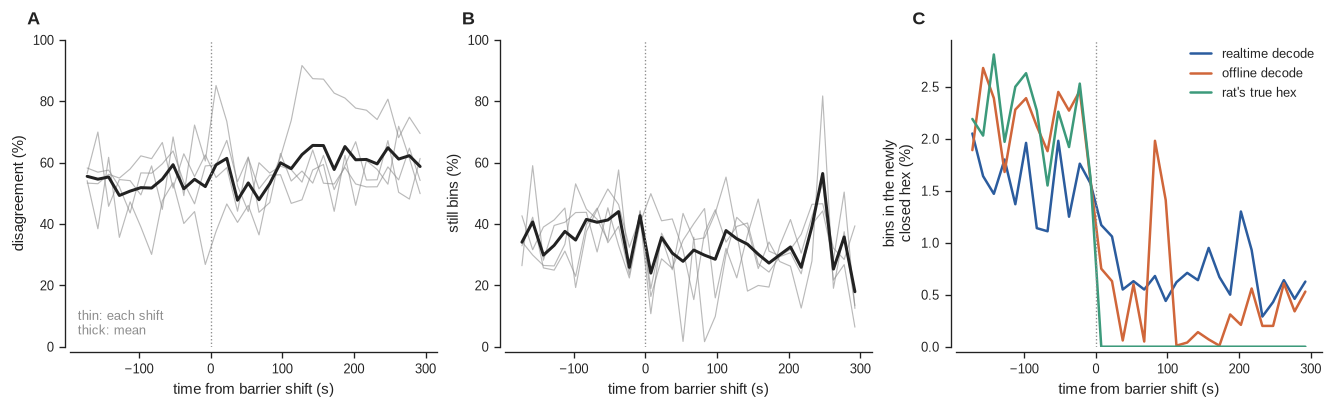

mean of each shift's 15 s windows — 3 min before vs the first 2 min after:


,disagree before %,disagree after %,still before %,still after %,"realtime in newly closed hex, after %","offline in newly closed hex, after %"
shift,,,,,,
1,43.2,49.5,39.5,19.6,1.3,2.3
2,58.2,53.7,37.6,29.8,0.3,0.1
3,57.0,61.0,37.8,36.9,0.8,0.1
4,55.3,56.2,33.8,36.5,0.4,0.2


which closed hexes realtime decodes (% of its 30,982 closed-hex decodes; zero-spike share 11.3% vs 15.8% overall):


rt_dec,17,23,5,37,39,19,18,31
% of closed-hex decodes,41.5,21.5,12.2,9.2,4.9,4.7,3.1,1.4
closed,all epoch,all epoch,all epoch,all epoch,all epoch,some blocks,some blocks,some blocks


In [23]:
WIN_PRE, WIN_POST, STEP = 180, 300, 15     # s before / after each shift, window width
edges_s = np.arange(-WIN_PRE, WIN_POST + STEP, STEP)
ctr = edges_s[:-1] + STEP / 2
t_sec = (pairs.minute * 60).to_numpy()
rows = []
for k_, m_ in enumerate(SHIFT_MIN):
    newly = sorted(set(CLOSED[k_ + 1]) - set(CLOSED[k_]))
    rel = t_sec - m_ * 60
    sel = (rel >= -WIN_PRE) & (rel < WIN_POST)
    d = pairs[sel].assign(w=np.digitize(rel[sel], edges_s) - 1)
    g = d.groupby('w')
    rows.append(pd.DataFrame({'shift': k_ + 1, 'x': ctr[g.size().index],
                              'disagree': 100 * (1 - g.agree.mean()), 'still': 100 * g.still.mean(),
                              'rt_new': 100 * g.rt_dec.agg(lambda s: s.isin(newly).mean()),
                              'of_new': 100 * g.of_dec.agg(lambda s: s.isin(newly).mean()),
                              'rat_new': 100 * g.of_act.agg(lambda s: s.isin(newly).mean())}))
SL = pd.concat(rows)
mean_sl = SL.groupby('x').mean(numeric_only=True)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharex=True)
for ax, col, yl in [(axes[0], 'disagree', 'disagreement (%)'), (axes[1], 'still', 'still bins (%)')]:
    for _, d in SL.groupby('shift'):
        ax.plot(d.x, d[col], color=MUTED, lw=0.7, alpha=0.6)
    ax.plot(mean_sl.index, mean_sl[col], color=INK, lw=1.8)
    ax.set_ylim(0, 100); ax.set_ylabel(yl)
ax = axes[2]
for col, c, lab in [('rt_new', RT, 'realtime decode'), ('of_new', OF, 'offline decode'), ('rat_new', TRUE, "rat's true hex")]:
    ax.plot(mean_sl.index, mean_sl[col], color=c, label=lab)
ax.set_ylim(0, None); ax.set_ylabel('bins in the newly\nclosed hex (%)')
ax.legend(loc='upper right')
for ax in axes:
    ax.axvline(0, color=MUTED, lw=0.8, ls=':')
    ax.set_xlabel('time from barrier shift (s)')
axes[0].annotate('thin: each shift\nthick: mean', xy=(0.02, 0.04), xycoords='axes fraction', fontsize=7.5, color=MUTED)
letter(axes)
show(fig, 'fig18_barrier_shift_locked')

win = lambda lo, hi: SL[(SL.x >= lo) & (SL.x < hi)].groupby('shift').mean(numeric_only=True)
before, after = win(-WIN_PRE, 0), win(0, 120)
print('mean of each shift\'s 15 s windows — 3 min before vs the first 2 min after:')
display(pd.DataFrame({'disagree before %': before.disagree, 'disagree after %': after.disagree,
                      'still before %': before.still, 'still after %': after.still,
                      'realtime in newly closed hex, after %': after.rt_new,
                      'offline in newly closed hex, after %': after.of_new}).round(1))

cd_ = pairs[pairs.rt_closed]
print(f'which closed hexes realtime decodes (% of its {len(cd_):,} closed-hex decodes; '
      f'zero-spike share {100*(cd_.spikes == 0).mean():.1f}% vs {100*(pairs.spikes == 0).mean():.1f}% overall):')
share = (100 * cd_.rt_dec.value_counts(normalize=True)).round(1).head(8)
display(pd.DataFrame({'% of closed-hex decodes': share,
                      'closed': ['all epoch' if h in ALWAYS_CLOSED or all(h in c for c in CLOSED) else 'some blocks'
                                 for h in share.index]}).T)

**Figure 18.** The four barrier shifts aligned at time 0 (15 s windows). **A**, Disagreement. **B**, Share of
still bins (thin: each shift; thick: mean). **C**, Share of bins in which the realtime decode (blue), the offline
decode (orange) or the rat (green) is in the hex the shift has just closed (mean of the four shifts).

**Takeaway.**

- **No consistent jump at the shifts.** Averaged over the four shifts, disagreement is 53% in the 3 minutes before and
  55% in the 2 minutes after. Shift by shift: 43 → 50%, 58 → 54%, 57 → 61%, 55 → 56%. Only the first shift shows a clear
  rise, and that is the hex-11 pause above.
- **Neither decoder clings to the hex that was just closed.** In the 2 minutes after a shift, realtime decodes the newly
  closed hex in 0.3–1.3% of bins and offline in 0.1–2.3%, against about 2% of bins with the rat there beforehand. So
  a shift doesn't leave realtime decoding the old route.
- **Most of realtime's closed-hex decodes go to hexes that are closed all epoch:** 17, 23, 5, 37 and 39 account for
  89% of them (hex 17 alone for 42%). Only about 9% go to hexes a shift closed (19, 18, 31). They are not empty-bin
  artefacts either: 11% are zero-spike bins, against 16% overall. Why the likelihood lands on never-visited hexes
  isn't tested here.

### 13c · How much would knowing the barriers help?

The direct test: replay the realtime filter (as in §14) with each barrier block's closed hexes removed from the
transition matrix — the same construction the decoder uses when `blocked_hexes` is set (`_build_hex_transmat` in
`decoder_process.py`: prune the maze graph, build the random walk, zero the closed rows and columns). Belief in a closed
hex then dies within one bin and cannot come back. Four variants, crossing *barriers known* with *a slower prior*
(movement_var 0.1, the value §14 picks out). First check: the "as run" variant must reproduce the logged decode.

"as run" replay reproduces the logged decode in 99.9996% of bins; bins where belief hit zero and was reset to uniform: {'as run (var 1, no barriers)': np.int64(0), 'barriers known (var 1)': np.int64(0), 'slower prior (var 0.1)': np.int64(0), 'both (var 0.1 + barriers)': np.int64(0)}


,agree %,agree running %,agree still %,decodes in a closed hex %
variant,,,,
"as run (var 1, no barriers)",43.0,53.2,35.8,6.8
barriers known (var 1),45.5,54.4,40.0,0.0
slower prior (var 0.1),58.0,61.0,57.7,0.5
both (var 0.1 + barriers),59.6,61.4,60.8,0.0


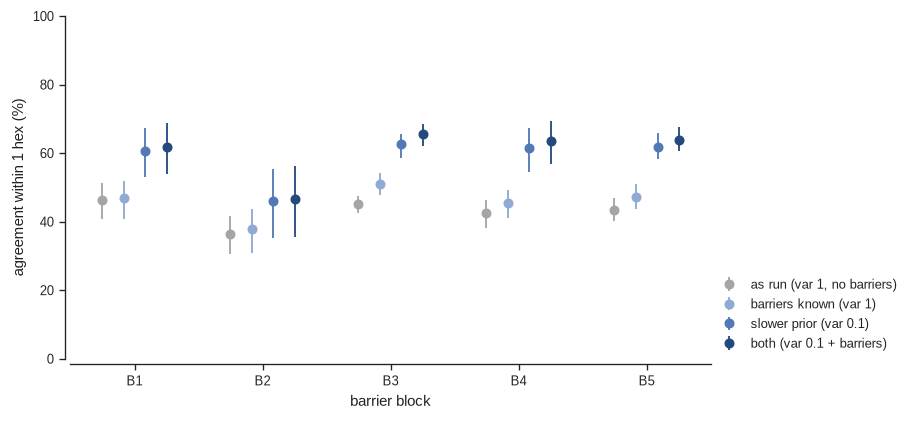

In [24]:
def rw_matrix(var, closed):
    # the decoder's own construction for a hex maze with blocked hexes
    T = transitions.hex_random_walk_transition_matrix(HEX_IDS, transitions.prune_hex_graph(adj, closed), var)
    return transitions.zero_blocked_hexes(T, [HEX_IDS.index(h) for h in closed])

VARIANTS = {'as run (var 1, no barriers)': (1.0, False), 'barriers known (var 1)': (1.0, True),
            'slower prior (var 0.1)': (0.1, False), 'both (var 0.1 + barriers)': (0.1, True)}
VCOL = ['#a5a5a5', '#8faad3', '#5279b5', '#24497f']
TB = [np.stack([rw_matrix(v, CLOSED[b] if use else []) for v, use in VARIANTS.values()]) for b in range(N_BB)]
bin_bb = np.searchsorted(SHIFT_MIN, rt.bin_seconds.to_numpy() / 60, side='right')   # barrier block of every realtime bin

def replay_blocks(T_blocks, lik, p0, bb):
    # posterior_t ∝ lik_t * (posterior_{t-1} @ T[block of t]); returns argmax hex ids and how often belief hit zero
    p = np.repeat(p0[None], T_blocks[0].shape[0], 0)
    out, resets = np.empty((len(lik), p.shape[0]), np.int8), np.zeros(p.shape[0], int)
    for t, l in enumerate(lik):
        p = l * np.matmul(p[:, None, :], T_blocks[bb[t]])[:, 0, :]
        s = p.sum(1, keepdims=True)
        resets += (s[:, 0] <= 0)
        p = np.where(s > 0, p / np.where(s > 0, s, 1), 1 / p.shape[1])
        out[t] = p.argmax(1)
    return out + 1, resets

dec_v, resets = replay_blocks(TB, LIK, POST[0], bin_bb)
print(f'"as run" replay reproduces the logged decode in {100*(dec_v[:, 0] == rt.decoded_hex.to_numpy()).mean():.4f}% of bins;'
      f' bins where belief hit zero and was reset to uniform: {dict(zip(VARIANTS, resets))}')

dv = dec_v[ROWS]
RES, rows = {}, []
for k_, name in enumerate(VARIANTS):
    ok = pd.Series(hex_steps(dv[:, k_], pairs.of_dec).clip(0) <= AGREE_TOL, index=pairs.index)
    RES[name] = boot_rate(ok, pairs.barrier_block)
    in_closed = CLOSED_MASK[pairs.barrier_block - 1, dv[:, k_]]
    rows.append({'variant': name, 'agree %': 100 * ok.mean(),
                 'agree running %': 100 * ok[pairs.running].mean(), 'agree still %': 100 * ok[pairs.still].mean(),
                 'decodes in a closed hex %': 100 * in_closed.mean()})
display(pd.DataFrame(rows).set_index('variant').round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
xb = np.arange(N_BB)
for k_, (name, c) in enumerate(zip(VARIANTS, VCOL)):
    r = RES[name]
    off = (k_ - 1.5) * 0.17
    ax.errorbar(xb + off, r.rate, yerr=[r.rate - r.lo, r.hi - r.rate], fmt='o', color=c, ms=5, elinewidth=1.1,
                capsize=0, label=name)
ax.set_xticks(xb, [f'B{b+1}' for b in xb])
ax.set_xlim(-0.5, N_BB - 0.5)
ax.set_ylim(0, 100)
ax.set_xlabel('barrier block')
ax.set_ylabel(f'agreement within {AGREE_TOL} hex (%)')
ax.legend(loc='lower left', bbox_to_anchor=(1.0, 0.0))
show(fig, 'fig19_barrier_aware_replay')

**Figure 19.** Agreement with offline (≤ 1 hex) per barrier block when the realtime filter is replayed on its
logged likelihoods: as run, with that block's closed hexes removed from the transition matrix, with a slower random
walk (movement_var 0.1), and with both. Whiskers: 95% CI.

**Takeaway.** Telling the decoder where the barriers are helps, but only a little.

- **The replay check passes:** the "as run" variant reproduces the logged decode in 99.9996% of bins.
- **Barriers known:** agreement rises from 43.0% to 45.5% overall, 35.8% → 40.0% at rest and 53.2% → 54.4% while
  running, and closed-hex decodes drop from 6.8% to 0. The gain is similar in every block (largest in B3, about
  +6 points).
- **A slower prior does far more:** 58.0%, and both together 59.6% (60.8% at rest). On top of the slower prior,
  barrier knowledge adds 1.5–3 points.
- **B2 stays the worst block under every variant** (36–47%), which fits the hex-11 pause being a behavioural problem,
  not a barrier-bookkeeping one.
- **In practice:** giving the decoder the closed hexes is cheap and removes physically impossible decodes, but it is
  not what limits this decoder. The config currently takes one `blocked_hexes` list per run; following the barriers
  mid-session would need the rebuild hook `_build_hex_transmat` was written for.

## 14 · Prior sweep — replay the realtime filter with slower random walks

The realtime decoder logs its **likelihood** for every bin, and the likelihood does not depend on the prior (it comes
only from spikes and the encoding model — `compute_posterior` in `decoder_process.py`). So the recursive update

$$\text{posterior}_t \;\propto\; \text{likelihood}_t \times (\text{posterior}_{t-1} \cdot T)$$

can be re-run here, in numpy, with any transition matrix $T$ — no Trodes needed. First check: with the run's own
matrix (random walk, var 1) the replay must reproduce the logged decode.

`movement_var` is the random walk's variance in hops² per 6 ms bin. To make it concrete, the table's *prior drift*
column says how many hex steps per second the prior alone would spread belief. Compare that with the rat, which
changes hex about 1.7 times per second (§8).

**Caveat.** A stickier prior makes the realtime decode look more like the offline *smoother*, but it could also flatten
real fast, non-local content (replay) — exactly what closed-loop detection is after. Panel C checks that: in the still
bins where offline decodes content ≥ 2 hexes from the rat, how often does each prior agree with offline?

replay with the run's own prior reproduces the logged decode in 99.9996% of bins


for scale: the rat moves 1.7 hex/s on average (3.6 while running); offline switches 9.2 hex/s and is non-local in 28.4% of rest-ripple bins
"agree on offline non-local at rest" is scored on the 20,109 still bins where offline decodes ≥2 hexes from the rat


,prior drift (hex steps/s),agree %,exact agree %,agree running %,agree still %,near rat %,hex switches /s,agree on offline non-local at rest %,non-local in rest ripples %
movement_var,,,,,,,,,
0.03,0.000,60.497,41.907,54.066,69.068,65.936,3.026,6.156,39.460
0.05,0.019,60.218,42.149,58.328,64.105,64.606,5.062,13.845,45.397
0.1,2.836,57.963,39.045,61.031,57.700,60.605,12.688,21.374,60.374
0.2,28.854,54.271,34.295,60.827,51.308,55.390,32.505,24.959,72.448
0.3,54.788,51.847,30.743,59.678,47.345,52.343,47.950,25.322,75.951
0.5,89.812,48.638,25.566,57.606,42.862,48.786,66.149,24.596,78.286
1.0,150.308,43.007,19.756,53.190,35.795,42.898,89.054,21.990,80.787
none,909.621,17.026,8.479,25.767,8.489,16.387,146.140,6.156,90.460


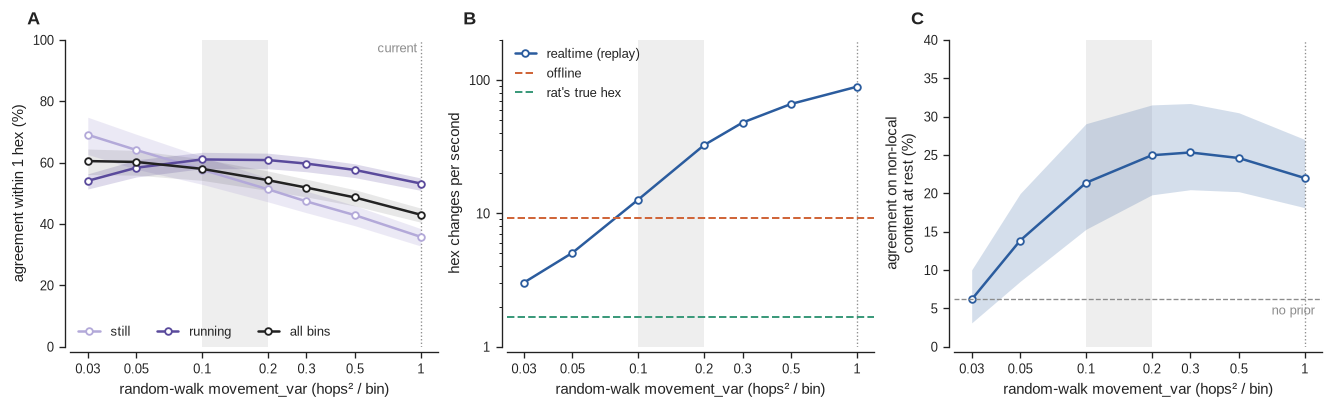

agreement (%) with 95% CI, as plotted:


all             running             still             nonlocal  \
              rate    lo    hi    rate    lo    hi  rate    lo    hi     rate   
movement_var                                                                    
0.03          60.5  56.1  64.4    54.1  51.4  56.3  69.1  62.6  74.8      6.2   
0.05          60.2  55.9  64.0    58.3  55.3  60.9  64.1  57.8  69.2     13.8   
0.10          58.0  54.2  61.2    61.0  58.0  63.4  57.7  52.9  62.0     21.4   
0.20          54.3  50.9  57.3    60.8  58.0  63.1  51.3  47.2  55.0     25.0   
0.30          51.8  48.8  54.6    59.7  57.0  61.8  47.3  43.7  50.7     25.3   
0.50          48.6  45.9  51.1    57.6  55.1  59.6  42.9  39.4  46.0     24.6   
1.00          43.0  40.6  45.2    53.2  50.9  55.0  35.8  32.8  38.5     22.0   

                          
                lo    hi  
movement_var              
0.03           3.1  10.0  
0.05           8.5  20.0  
0.10          15.3  29.1  
0.20          19.8  31.5  
0.30          20.5  31.7  
0.50          20.2  30.5  
1.00          18.1  27.0

In [25]:
VARS = [0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
PRIORS = {v: transitions.hex_random_walk_transition_matrix(HEX_IDS, adj, v) for v in VARS}
PRIORS['none'] = transitions.hex_uniform_transition_matrix(len(HEX_IDS))   # flat prior = likelihood only

def replay(transmats, lik, p0):
    # posterior_t ∝ lik_t * (posterior_{t-1} @ T), for several T at once; returns argmax column per bin
    T = np.stack(transmats)
    p = np.repeat(p0[None], len(T), 0)
    out = np.empty((len(lik), len(T)), np.int8)
    for t, l in enumerate(lik):
        p = l * np.matmul(p[:, None, :], T)[:, 0, :]
        s = p.sum(1, keepdims=True)
        p = np.where(s > 0, p / np.where(s > 0, s, 1), 1 / p.shape[1])   # guard; never triggered in this run
        out[t] = p.argmax(1)
    return out

dec_all = replay(list(PRIORS.values()), LIK, POST[0]) + 1          # hex ids, all realtime bins
logged  = list(PRIORS).index(1.0)
print(f"replay with the run's own prior reproduces the logged decode in "
      f"{100*(dec_all[:, logged] == rt.decoded_hex.to_numpy()).mean():.4f}% of bins")

dec = dec_all[ROWS]
rest_rip = (pairs.still & pairs.ripple & (pairs.of_act > 0)).to_numpy()
rest_nl  = (pairs.still & (pairs.of_err >= 2)).to_numpy()        # offline decodes non-local content at rest
D_hex    = HEXDIST[1:NH, 1:NH]
rows, ci = [], {}
for col, (name, T) in enumerate(PRIORS.items()):
    d, e = hex_steps(dec[:, col], pairs.of_dec), hex_steps(dec[:, col], pairs.of_act)
    ok = pd.Series(d.clip(0) <= AGREE_TOL, index=pairs.index)
    ci[name] = {grp: boot_rate(ok[m], pd.Series(0, index=pairs.index[m]), pairs[m]).iloc[0]
                for grp, m in [('running', pairs.running.to_numpy()), ('still', pairs.still.to_numpy()),
                               ('all', np.ones(len(pairs), bool)), ('nonlocal', rest_nl)]}
    rows.append({
        'movement_var'               : name,
        'prior drift (hex steps/s)'  : (T * D_hex).sum(1).mean() / BIN_S,   # how far the prior alone spreads belief
        'agree %'                    : 100 * ok.mean(),
        'exact agree %'              : 100 * (d == 0).mean(),
        'agree running %'            : 100 * ok[pairs.running].mean(),
        'agree still %'              : 100 * ok[pairs.still].mean(),
        'near rat %'                 : 100 * (e[pairs.of_act > 0].clip(0) <= AGREE_TOL).mean(),
        'hex switches /s'            : switches_per_s(dec[:, col]),
        'agree on offline non-local at rest %': 100 * ok[rest_nl].mean(),
        'non-local in rest ripples %': 100 * (e[rest_rip] >= 2).mean(),
    })
sweep = pd.DataFrame(rows).set_index('movement_var')
print(f"for scale: the rat moves {switches_per_s(pairs.of_act):.1f} hex/s on average "
      f"({switches_per_s(pairs.of_act[pairs.running]):.1f} while running); offline switches "
      f"{switches_per_s(pairs.of_dec):.1f} hex/s and is non-local in {100*(pairs.of_err[rest_rip] >= 2).mean():.1f}% "
      f"of rest-ripple bins")
print(f'"agree on offline non-local at rest" is scored on the {rest_nl.sum():,} still bins where offline decodes '
      f'≥2 hexes from the rat')
display(sweep.round(3))

def ci_of(grp):
    return pd.DataFrame([ci[v_][grp] for v_ in VARS], index=VARS)

v = np.array(VARS)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
a0, a1, a2 = axes
for ax in axes:
    ax.axvspan(0.1, 0.2, color=SHADE, lw=0, zorder=0)
    ax.axvline(1.0, color=MUTED, lw=0.8, ls=':', zorder=0)
    ax.set_xscale('log')
    ax.set_xticks(v, [f'{x:g}' for x in v])
    ax.minorticks_off()
    ax.set_xlim(0.025, 1.2)
    ax.set_xlabel('random-walk movement_var (hops² / bin)')
for lab, grp, c, ba in [('still', 'still', STILL_C, .25), ('running', 'running', RUN_C, .2), ('all bins', 'all', INK, .1)]:
    ci_line(a0, v, ci_of(grp), c, label=lab, band_alpha=ba)
a0.set_ylim(0, 100)
a0.set_ylabel(f'agreement within {AGREE_TOL} hex (%)')
a0.legend(loc='lower left', ncol=3)
a0.annotate('current', xy=(1.0, 1.0), xycoords=('data', 'axes fraction'), xytext=(-2, -2),
            textcoords='offset points', ha='right', va='top', fontsize=7.5, color=MUTED)

a1.plot(v, sweep.loc[VARS, 'hex switches /s'], color=RT, marker='o', mfc='white', mew=1.1, label='realtime (replay)')
a1.axhline(switches_per_s(pairs.of_dec), color=OF, lw=1.2, ls='--', label='offline')
a1.axhline(switches_per_s(pairs.of_act), color=TRUE, lw=1.2, ls='--', label="rat's true hex")
a1.set_yscale('log')
a1.yaxis.set_major_formatter(PLAIN)
a1.set_ylim(1, 200)
a1.set_ylabel('hex changes per second')
a1.legend(loc='upper left')

ci_line(a2, v, ci_of('nonlocal'), RT)
a2.axhline(sweep.loc['none', 'agree on offline non-local at rest %'], color=MUTED, lw=0.8, ls='--')
a2.annotate('no prior', xy=(0.98, sweep.loc['none', 'agree on offline non-local at rest %']),
            xycoords=('axes fraction', 'data'), xytext=(0, -3), textcoords='offset points',
            fontsize=7.5, color=MUTED, ha='right', va='top')
a2.set_ylim(0, 40)
a2.set_ylabel('agreement on non-local\ncontent at rest (%)')
letter(axes)
show(fig, 'fig20_prior_sweep')
print('agreement (%) with 95% CI, as plotted:')
display(pd.concat({g: ci_of(g)[['rate', 'lo', 'hi']] for g in ['all', 'running', 'still', 'nonlocal']},
                  axis=1).rename_axis('movement_var').round(1))

**Figure 20.** The realtime filter replayed on its logged likelihoods with random-walk priors of different
variance (log x axis). Dotted line: the variance this run used (1); grey band: 0.1–0.2. **A**, Agreement with
offline for still, running and all bins. **B**, How often the replayed decode changes hex, with offline (orange) and
the rat (green) for reference. **C**, Agreement on the 20,109 still bins where offline decodes ≥ 2 hexes from the rat;
dashed line: no prior. Bands: 95% CI.

**Takeaway.**

- **The replay is faithful.** With the run's own prior it reproduces the logged decode in 99.9996% of bins.
- **The current prior is far too loose.** On its own it spreads belief about 150 hex steps per second; the rat moves
  1.7 (3.6 while running). Slowing it helps almost everything. At `movement_var` 0.1, agreement rises from 43% to
  58% (exact: 20% → 39%), near-the-rat from 43% to 61%, and jumping falls from 89 to 13 switches/s (offline: 9).
- **There is a limit, and the replay check finds it.** The stickiest priors (0.03–0.05) score highest overall only
  because they park on the rat's location. When offline decodes non-local content at rest, they agree just 6–14% of
  the time, down from 22% now; at 0.03 that is as bad as having no prior. Running agreement also falls below 0.1,
  because the decode starts to lag the moving rat.
- **The sweet spot is about 0.1–0.2.** Agreement, accuracy and jumpiness all improve over the current value of 1
  (overall agreement 54–61% at 0.1 against 41–45% now, 95% CIs), while agreement on non-local content stays about
  where it is now: 21–25% against 22%. Those non-local numbers rest on far fewer bins, and their CIs overlap
  (roughly 15–32%), so this run cannot rank 0.1–1 on that measure. Only the stickiest prior is clearly worse
  (0.03: 3–10%).

What this does *not* show: whether 0.1–0.2 *detects* replay better online. That needs replay events scored directly,
not agreement with a smoother.

---
# Appendix

Supporting checks and the earlier version's still-valid sections, updated to `decode_hex_any` and the 1-hex rule
where that applies. Two earlier sections were removed because they no longer describe this run:

- *"`transmat_bias` is an inert knob"* — true of the `adjacency` matrix, but this run used `random_walk`, which has
  no bias parameter (§14 covers the prior instead).
- *"The run lost 59% of its spikes"* — the run's own log says 0.29% were dropped (A1).

### A1 · Time alignment and run health

If the two decodes were misaligned in time, shifting one of them would raise agreement. Panel A shows it doesn't:
agreement is highest at zero shift (note the narrow y-range — the whole curve spans about 2 points). Panel B is the
same test on the two pipelines' *tracked* position. It peaks 30–45 ms to the left, meaning the realtime position stream
runs that far behind the offline tracking.

realtime record: -13.86 s before the offline start, +3.21 s after the offline end (those bins are unmatched)


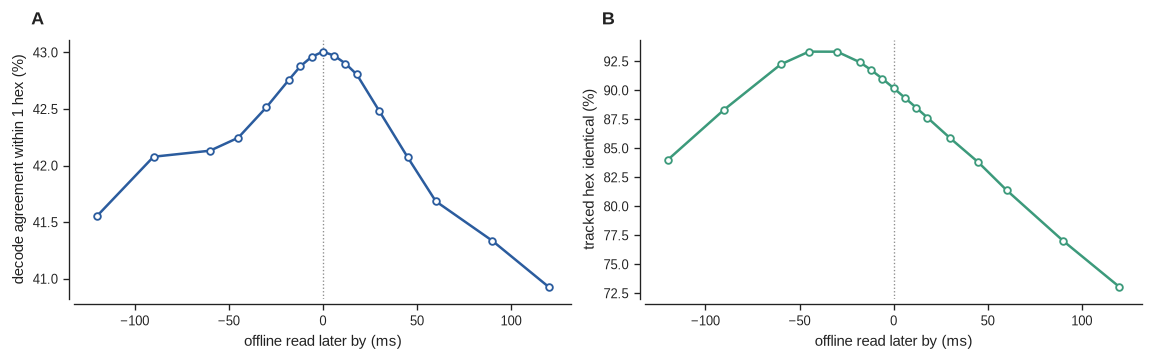

tracked position agrees best at lag -45 ms; decode agreement best at lag 0 ms
run health: Dropped spikes: 3999, Total: 1402000, (0.2852 %)


In [26]:
print(f'realtime record: {t_rt[0]-t_of[0]:+.2f} s before the offline start, '
      f'{t_rt[-1]-t_of[-1]:+.2f} s after the offline end (those bins are unmatched)')

def at_lag(lag_ms):
    # agreement when the offline series is read lag_ms later than the realtime bin
    tq = t_rt + lag_ms / 1e3
    ii = np.searchsorted(t_of, tq).clip(1, len(t_of) - 1)
    jj = np.where(np.abs(tq - t_of[ii - 1]) <= np.abs(tq - t_of[ii]), ii - 1, ii)
    ok = np.abs(tq - t_of[jj]) <= MATCH_TOL
    d  = hex_steps(rt.decoded_hex.to_numpy()[ok], of.decode_hex_any.to_numpy()[jj[ok]])
    pos = rt.actual_hex.to_numpy()[ok] == of.hex.to_numpy()[jj[ok]]
    return 100 * (d.clip(0) <= AGREE_TOL).mean(), 100 * pos.mean()

lags = [-120, -90, -60, -45, -30, -18, -12, -6, 0, 6, 12, 18, 30, 45, 60, 90, 120]
lag_tab = pd.DataFrame([at_lag(l) for l in lags], index=pd.Index(lags, name='lag_ms'),
                       columns=['decodes agree %', 'tracked hex same %'])
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 2.9), sharex=True)
for ax, col, c, yl in [(a0, 'decodes agree %', RT, f'decode agreement within {AGREE_TOL} hex (%)'),
                       (a1, 'tracked hex same %', TRUE, 'tracked hex identical (%)')]:
    ax.axvline(0, color=MUTED, lw=0.8, ls=':')
    ax.plot(lag_tab.index, lag_tab[col], color=c, marker='o', mfc='white', mew=1.1)
    ax.set_xlabel('offline read later by (ms)')
    ax.set_ylabel(yl)
letter([a0, a1])
show(fig, 'figA1_alignment')
print(f"tracked position agrees best at lag {lag_tab['tracked hex same %'].idxmax()} ms; "
      f"decode agreement best at lag {lag_tab['decodes agree %'].idxmax()} ms")

logs  = glob.glob(f'{RUN_DIR}/*_debug.log/*')
drops = [l for f in logs for l in open(f, errors='ignore') if 'Dropped spikes' in l]
print('run health:', drops[-1].split('DecoderManager: ')[-1].strip() if drops else 'no "Dropped spikes" line in the debug log')

**Figure A1.** Effect of shifting the offline series in time relative to the realtime one (positive = offline
read later). **A**, Decode agreement (≤ 1 hex). **B**, The two pipelines' tracked hex is identical.

**Takeaway.** Decode agreement peaks at zero shift, so the bins are aligned. Tracked position peaks at
−30 to −45 ms: the realtime position stream runs about that far behind the offline tracking. The run dropped 0.29% of
its spikes.

### A2 · Are the hex ids the same in both pipelines?

Nothing above means anything unless both pipelines label the rat's true position the same way. They agree on the
tracked hex most of the time, and the mismatches are adjacent hexes at high speed — tracking latency (A1), not a
numbering difference.

In [27]:
rt_act = rt.actual_hex.to_numpy()[match]
v_ok   = (rt_act > 0) & (pairs.of_act.to_numpy() > 0)
same   = rt_act[v_ok] == pairs.of_act.to_numpy()[v_ok]
sep    = hex_steps(rt_act[v_ok][~same], pairs.of_act.to_numpy()[v_ok][~same])
print(f'tracked hex identical in both pipelines: {100*same.mean():.2f}% of {v_ok.sum():,} bins')
print(f'   median speed when they differ: {pairs.speed[v_ok][~same].median():.1f} cm/s   '
      f'(when the same: {pairs.speed[v_ok][same].median():.1f} cm/s)')
print(f'   when they differ, they are {np.median(sep):.0f} hex step apart (median); '
      f'{100*(sep == 1).mean():.1f}% are neighbours')

tracked hex identical in both pipelines: 90.29% of 457,033 bins
   median speed when they differ: 46.2 cm/s   (when the same: 4.7 cm/s)
   when they differ, they are 1 hex step apart (median); 94.4% are neighbours


### A3 · Accuracy against the rat's true hex, with baselines

Agreement says nothing about who is right; this does. A decode counts as correct if it lands within `d` hex steps
of the rat. Tolerance inflates every score, so it only means something next to baselines that get the same tolerance:

| baseline | what it is |
|---|---|
| **uniform** | guess one of the 49 hexes at random |
| **occupancy** | guess by drawing from where the rat actually spends its time |
| **best constant** | *always* name one single hex, chosen to maximise the score — uses no neural data at all |

The last one is the bar that matters: a decoder that can't beat "always say hex 2" isn't adding information.

realtime %  offline %  uniform %  occupancy %  \
                 tolerance                                                  
all              <= 0             19.2       67.7        2.0         13.1   
                 <= 1             42.9       86.7        5.8         16.8   
                 <= 2             52.8       89.2       12.4         20.7   
                 <= 3             58.6       90.3       20.3         25.2   
running >10 cm/s <= 0             25.6       52.7        2.0          3.4   
                 <= 1             53.8       87.4        7.1          9.5   
                 <= 2             66.5       91.7       15.6         17.0   
                 <= 3             73.8       93.3       26.3         26.4   
still <2 cm/s    <= 0             13.5       83.9        2.0         40.5   
                 <= 1             34.4       86.2        4.4         40.9   
                 <= 2             40.9       86.8        9.0         41.1   
                 <= 3             44.3       87.0       13.9         41.4   

                            best constant %  that hex  
                 tolerance                             
all              <= 0                  29.0         2  
                 <= 1                  33.3        49  
                 <= 2                  36.7        47  
                 <= 3                  46.1        42  
running >10 cm/s <= 0                   7.2         2  
                 <= 1                  15.7        49  
                 <= 2                  25.7        30  
                 <= 3                  44.1        30  
still <2 cm/s    <= 0                  54.9         2  
                 <= 1                  55.1        49  
                 <= 2                  55.6        47  
                 <= 3                  59.0        32

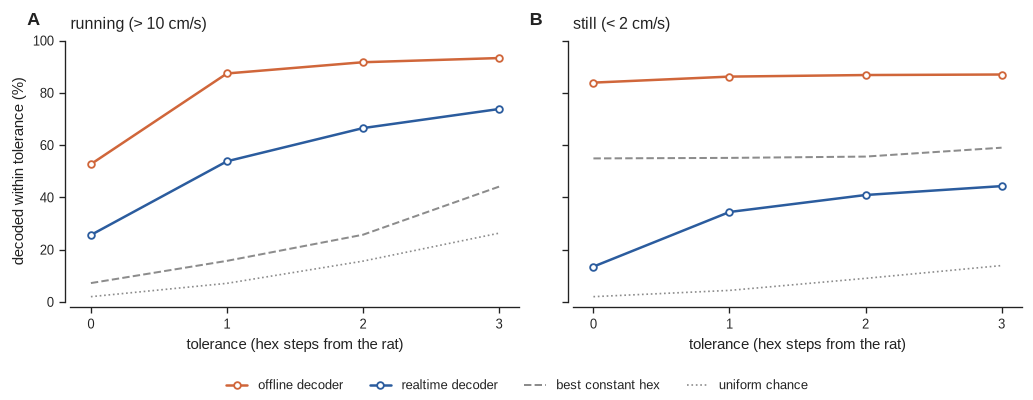

decoder vs decoder:


,agree %,chance %,kappa
tolerance,,,
<= 0,19.756,3.777,0.166
<= 1,43.007,10.940,0.360
<= 2,51.970,17.055,0.421
<= 3,58.382,24.390,0.450


In [28]:
HEXES = np.arange(1, NH)
D_gt  = HEXDIST[np.ix_(HEXES, HEXES)]                      # D_gt[guess, true], hex steps
va    = pairs[pairs.of_act > 0]

def tolerance_table(df):
    p_true = df.of_act.value_counts(normalize=True).reindex(HEXES, fill_value=0).to_numpy()
    rows = []
    for d in range(4):
        within = (D_gt >= 0) & (D_gt <= d)                  # within[guess, true]
        hit = (within * p_true[None, :]).sum(1)             # score of each constant guess
        rows.append({'tolerance': f'<= {d}',
                     'realtime %'     : 100 * df.rt_err.between(0, d).mean(),
                     'offline %'      : 100 * df.of_err.between(0, d).mean(),
                     'uniform %'      : 100 * float((within.mean(0) * p_true).sum()),
                     'occupancy %'    : 100 * float(hit @ p_true),
                     'best constant %': 100 * float(hit.max()),
                     'that hex'       : int(HEXES[hit.argmax()])})
    return pd.DataFrame(rows).set_index('tolerance').round(1)

tabs = {lab: tolerance_table(va[sel]) for lab, sel in
        [('all', slice(None)), ('running >10 cm/s', va.running), ('still <2 cm/s', va.still)]}
display(pd.concat(tabs))

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.2), sharey=True)
ds = np.arange(4)
for ax, (lab, key) in zip(axes, [('running (> 10 cm/s)', 'running >10 cm/s'), ('still (< 2 cm/s)', 'still <2 cm/s')]):
    t = tabs[key]
    ax.plot(ds, t['offline %'],  color=OF, marker='o', mfc='white', mew=1.1, label='offline decoder')
    ax.plot(ds, t['realtime %'], color=RT, marker='o', mfc='white', mew=1.1, label='realtime decoder')
    ax.plot(ds, t['best constant %'], color=MUTED, lw=1.2, ls='--', label='best constant hex')
    ax.plot(ds, t['uniform %'], color=MUTED, lw=1, ls=':', label='uniform chance')
    ax.set_title(lab)
    ax.set_xticks(ds)
    ax.set_ylim(0, 100)
    ax.set_xlabel('tolerance (hex steps from the rat)')
axes[0].set_ylabel('decoded within tolerance (%)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
letter(axes)
show(fig, 'figA3_accuracy_vs_baselines')

# decoder-vs-decoder agreement at each tolerance, chance-corrected (kappa) using each decoder's own hex frequencies
pr = pairs.rt_dec.value_counts(normalize=True).reindex(HEXES, fill_value=0).to_numpy()
po = pairs.of_dec.value_counts(normalize=True).reindex(HEXES, fill_value=0).to_numpy()
rows = []
for d in range(4):
    ok = pairs.d_dec.between(0, d)
    pe = float(pr @ ((D_gt >= 0) & (D_gt <= d)) @ po)
    rows.append({'tolerance': f'<= {d}', 'agree %': 100 * ok.mean(), 'chance %': 100 * pe,
                 'kappa': (ok.mean() - pe) / (1 - pe)})
print('decoder vs decoder:')
display(pd.DataFrame(rows).set_index('tolerance').round(3))

**Figure A3.** Share of bins decoded within *d* hex steps of the rat's true hex by the offline (orange) and
realtime (blue) decoders, against two guessers that use no neural data: the best single constant hex (dashed) and
uniform guessing (dotted). **A**, Running bins. **B**, Still bins.

**Takeaway.** While running, realtime clearly beats every baseline that uses no neural data (54% within
1 hex, against 16% for the best constant hex). At rest it does not: 34%, against 55% for always saying hex 2.
Offline is at 86–87% at rest.

### A4 · The raw traces

Twenty-five seconds of both decodes and the rat's true hex, on one hex axis (hexes ordered by graph distance from
hex 1, so vertical distance is roughly physical distance). The window is the one with the most speed variation, so it
contains both running and rest.

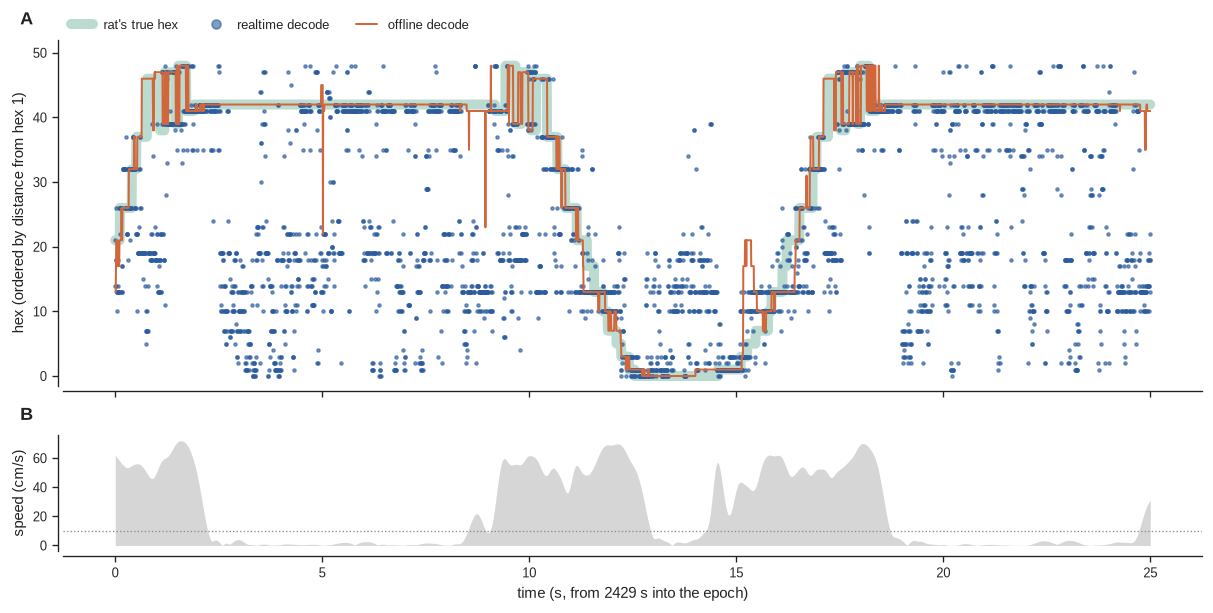

agreement in this window: 46.8%   running 45% of it


In [29]:
order  = np.argsort(HEXDIST[1, 1:NH], kind='stable')
hexord = np.arange(1, NH)[order]
to_rank = pd.Series(np.arange(len(hexord)), index=hexord)

W  = 25.0
t_s = pairs.minute * 60
sd = pd.Series(pairs.speed.to_numpy(), index=t_s).rolling(int(W / BIN_S), min_periods=1).std()
t0 = float(sd.idxmax()) - W / 2
sl = pairs[(t_s >= t0) & (t_s < t0 + W)]
x  = t_s[sl.index] - t0

fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, height_ratios=[3, 1])
a0.plot(x, to_rank.reindex(sl.of_act.where(sl.of_act > 0)).to_numpy(), lw=6, color=TRUE, alpha=.35, label="rat's true hex")
a0.plot(x, to_rank.reindex(sl.rt_dec).to_numpy(), ls='none', marker='o', ms=1.8, color=RT, alpha=.6, label='realtime decode')
a0.plot(x, to_rank.reindex(sl.of_dec).to_numpy(), lw=1.2, color=OF, label='offline decode')
a0.set_ylim(-1.5, 52)
a0.set_ylabel('hex (ordered by distance from hex 1)')
a0.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0), markerscale=3)
a1.fill_between(x, sl.speed, color=MUTED, alpha=.35, lw=0)
a1.axhline(RUN_SPEED, color=MUTED, lw=0.8, ls=':')
a1.set_ylabel('speed (cm/s)')
a1.set_xlabel(f'time (s, from {t0:.0f} s into the epoch)')
letter([a0, a1])
show(fig, 'figA4_raw_traces')
print(f'agreement in this window: {100*sl.agree.mean():.1f}%   running {100*sl.running.mean():.0f}% of it')

**Figure A4.** **A**, 25 s of the realtime decode (blue dots), the offline decode (orange) and the rat's true
hex (green); hexes ordered by graph distance from hex 1. **B**, Rat speed; dotted line: 10 cm/s.

**Takeaway.** While the rat runs, both decodes follow it. When it stops, offline stays on the rat, while
realtime scatters across the maze several times a second.

### A5 · Confusion structure — does realtime fall into favourite hexes?

If realtime's errors were unbiased noise, the joint distribution would be diffuse off the diagonal. Bright columns
mean it keeps landing on the same few hexes wherever offline says the rat's content is. Same hex order as A4.

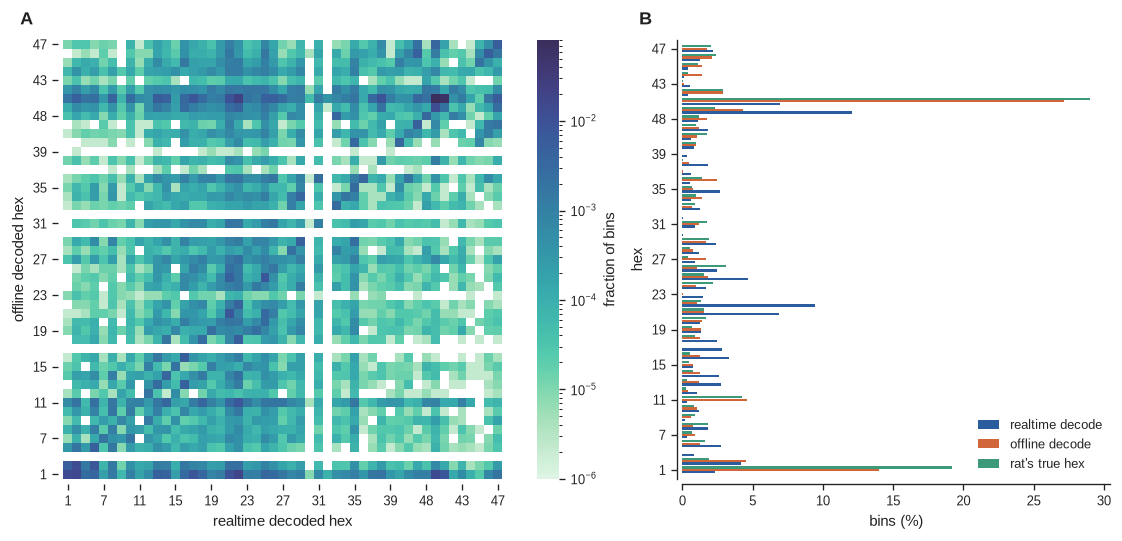

share of bins in each one's top-5 hexes: realtime 40.0%  offline 54.6%  rat 58.4%
entropy (bits, max 5.61): realtime 4.91  offline 4.33  rat 4.05


In [30]:
cm = pd.crosstab(pairs.of_dec, pairs.rt_dec).reindex(index=hexord, columns=hexord, fill_value=0)
M  = cm.to_numpy(float) / cm.to_numpy().sum()

fig, (ax, axb) = plt.subplots(1, 2, figsize=(10.5, 4.4), width_ratios=[3, 2])
im = ax.imshow(M, cmap=CM_SEQ, norm=mpl.colors.LogNorm(vmin=1e-6, vmax=M.max()), origin='lower', interpolation='nearest')
ax.set_xlabel('realtime decoded hex'); ax.set_ylabel('offline decoded hex')
ax.set_xticks(np.arange(len(hexord))[::4], hexord[::4]); ax.set_yticks(np.arange(len(hexord))[::4], hexord[::4])
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=.046)
cb.outline.set_visible(False)
cb.set_label('fraction of bins')

mr = pairs.rt_dec.value_counts(normalize=True).reindex(hexord, fill_value=0)
mo = pairs.of_dec.value_counts(normalize=True).reindex(hexord, fill_value=0)
ma = va.of_act.value_counts(normalize=True).reindex(hexord, fill_value=0)
yy = np.arange(len(hexord))
axb.barh(yy - .27, 100 * mr, height=.25, color=RT, label='realtime decode')
axb.barh(yy,       100 * mo, height=.25, color=OF, label='offline decode')
axb.barh(yy + .27, 100 * ma, height=.25, color=TRUE, label="rat's true hex")
axb.set_yticks(yy[::4], hexord[::4])
axb.set_ylim(-1, len(hexord))
axb.set_xlabel('bins (%)'); axb.set_ylabel('hex')
axb.legend(loc='lower right')
letter([ax, axb])
show(fig, 'figA5_confusion')

def top5(s):  return 100 * s.value_counts(normalize=True).nlargest(5).sum()
def ent(s):   p = s.value_counts(normalize=True).to_numpy(); return -(p * np.log2(p)).sum()
print(f"share of bins in each one's top-5 hexes: realtime {top5(pairs.rt_dec):.1f}%  "
      f"offline {top5(pairs.of_dec):.1f}%  rat {top5(va.of_act):.1f}%")
print(f'entropy (bits, max {np.log2(49):.2f}): realtime {ent(pairs.rt_dec):.2f}  '
      f'offline {ent(pairs.of_dec):.2f}  rat {ent(va.of_act):.2f}')

**Figure A5.** **A**, Joint distribution of offline (rows) and realtime (columns) decoded hexes, log colour
scale, hexes in the A4 order. **B**, Share of bins each decoder assigns to each hex, next to the rat's actual
occupancy.

**Takeaway.** Realtime's errors are not uniform noise. A few hexes are decoded far more often than the rat
is there: hex 49 in 12% of bins (rat 2.3%), hex 22 in 9.4% (rat 1.3%), hex 21 in 6.9% (rat 1.5%). It even outputs
hex 17, which the rat never visited. The corners go the other way: hex 2 in 6.9% of bins, against 29% for the rat.

### A6 · The corner blind spot

The rat spends about half the epoch in the corner hexes 1–3, mostly sitting still. Two pieces of the code shape what realtime can do there:

- The encoder only learns from moments when speed ≥ `encoder.vel_thresh` = 10 cm/s: `_is_training_epoch()`
  (`encoder_process.py:998`) gates both the stored marks (`:740`) and the encoder occupancy (`:889`). So "still" bins are
  decoded with a model built only from running.
- The encoder divides by normalised occupancy (`encoder_process.py:371`), and the decoder's no-spike term does the
  same (`decoder_process.py:308-316`). Hexes 1 and 2 hold the most occupancy of all, which pushes their likelihood down
  most.

The first table compares, for the corner hexes, how often the rat is there with how often each decoder says so. The
second holds speed fixed and asks whether *running through* the corner hexes is decoded worse than running elsewhere —
if so, it's the location, not the speed.

In [31]:
REST_HEXES = [1, 2, 3]
rows = [{'hex': h,
         'rat there %'     : 100 * (va.of_act == h).mean(),
         'offline says %'  : 100 * (pairs.of_dec == h).mean(),
         'realtime says %' : 100 * (pairs.rt_dec == h).mean()} for h in REST_HEXES]
blind = pd.DataFrame(rows).set_index('hex')
blind.loc['1-3 combined'] = blind.sum()
blind['realtime / rat'] = blind['realtime says %'] / blind['rat there %']
display(blind.round(3))

occ = np.load(sorted(glob.glob(f'{RUN_DIR}/*occupancy.npz'))[-1])['occupancy'].ravel()
top = sorted(zip(HEX_IDS, occ), key=lambda t: -t[1])[:5]
print('top-5 decoder-occupancy hexes:', [(int(h), int(c)) for h, c in top])

run = va[va.running].copy()
run['rest_hex'] = run.of_act.isin(REST_HEXES)
rows = []
for lo, hi in zip([10, 15, 20, 30, 40, 50], [15, 20, 30, 40, 50, 70]):
    a = run[run.rest_hex & run.speed.between(lo, hi, inclusive='left')]
    b = run[~run.rest_hex & run.speed.between(lo, hi, inclusive='left')]
    if min(len(a), len(b)) < MIN_N:
        continue
    rows.append({'speed band': f'{lo}-{hi} cm/s', 'n corners': len(a), 'n elsewhere': len(b),
                 'realtime near rat, corners %' : 100 * a.rt_err.between(0, AGREE_TOL).mean(),
                 'realtime near rat, elsewhere %': 100 * b.rt_err.between(0, AGREE_TOL).mean(),
                 'spikes/30 ms corners': a.spk_recent.mean(), 'spikes/30 ms elsewhere': b.spk_recent.mean()})
display(pd.DataFrame(rows).set_index('speed band').round(2))

,rat there %,offline says %,realtime says %,realtime / rat
hex,,,,
1,19.191,13.972,2.298,0.120
2,28.992,27.155,6.941,0.239
3,2.888,2.894,0.370,0.128
1-3 combined,51.070,44.020,9.609,0.188


top-5 decoder-occupancy hexes: [(2, 4844), (1, 3370), (47, 2258), (46, 1947), (24, 1610)]


,n corners,n elsewhere,"realtime near rat, corners %","realtime near rat, elsewhere %",spikes/30 ms corners,spikes/30 ms elsewhere
speed band,,,,,,
10-15 cm/s,6825,8339,32.76,32.39,15.52,15.45
15-20 cm/s,5275,7637,34.12,34.33,15.89,16.99
20-30 cm/s,8037,14828,37.43,41.82,15.61,17.80
30-40 cm/s,5776,27901,52.04,53.55,16.29,17.50
40-50 cm/s,4839,52344,59.31,56.88,17.03,17.82
50-70 cm/s,2700,67484,57.70,64.23,17.10,18.36


**Takeaway.** The blind spot is still there: the rat is in hexes 1–3 51% of the time, but realtime names
them only 9.6% of the time (offline: 44%). It is a *rest* problem, not a *place* problem, though. At the same running
speed, realtime is about as good at the corners as elsewhere, with similar spike counts: within about 4 points up to
50 cm/s, and 6.5 points worse at 50–70 cm/s.